# A model- and domain-agnostic orchestrator for LLM agent swarms: cost–quality experiment

**Julián Andrés Mendoza Castro · Esteban Gaviria Zambrano** · Artificial Intelligence G1, Universidad Icesi · V3.4 · October 7, 2026

**Research question.** Do more agents and more communication improve quality enough to justify the extra cost? And does the *same* orchestration code keep working when the model and the domain change?

**What changed in V3.2–V3.4.** The main cost–quality experiment now runs on **DeepSeek `deepseek-flash`** through the official API, in **non-thinking mode** and under a **hard budget cap**. The two local Ollama models piloted in V3.1 (`llama3.2:3b`, `qwen2.5:3b`) are kept, unchanged, as **secondary evidence of portability**. Each backend writes to its own results folder and is analysed separately.

| Factor | Main experiment (DeepSeek API) |
|---|---|
| Architecture | `single` agent (baseline), `hierarchical` (queen → workers → queen), `mesh` (hierarchical + one all-to-all review round) |
| Workers *n* | 2, 4 |
| Model | `deepseek-flash` (DeepSeek-V4.1-Flash), thinking disabled |
| Domains | GSM8K-Platinum: 10 problems, exact match. **MATH-500 level 5** (added in V3.4, because DeepSeek was at the ceiling on GSM8K): 10 problems with integer answers, exact match. Cartagena trip planning: open task, rubric. |
| Repetitions | GSM8K: single agent sampled 3×, swarm configurations 2×. MATH: single 3×, swarm 1×. Cartagena: 3× per configuration. |
| Controls | identical prompts, temperature, parsing and scoring for every model and backend. Output limit: 2,048 tokens on DeepSeek (1,024 truncated its Cartagena answers in the pilot), 1,024 on the local models |
| Budget | `MAX_SPEND_USD` hard cap: every call is checked before it is sent, and every batch is checked against the projected cost |

**Two kinds of agnosticism** are kept apart throughout:
- **Engineering model agnosticism:** the same orchestration code runs DeepSeek (API), Llama and Qwen (local) by changing only the configuration. Shown by the DeepSeek grid plus the V3.1 local pilots.
- **Empirical model agnosticism:** the *relative* behaviour of the architectures is preserved when the model changes. The full grid runs only on DeepSeek, so every cross-model statement in this notebook is **exploratory**.

**Latency is compared only within one backend.** API latency and laptop-GPU latency come from different infrastructures and are never put on the same axis.

> **No result in this notebook is invented.** With `BACKEND = "mock"` the pipeline runs with fake answers and every figure is stamped **MOCK DATA**. Experimental numbers only come from real `deepseek` or `ollama` runs.

## Hypotheses and the evidence behind the design

| # | Hypothesis | Motivating evidence (see `factcheck.md`) |
|---|---|---|
| H1 | **Coordination cost is structural.** Calls and messages are fixed by the topology (2n vs. n(n+1) messages). Tokens relative to the single agent grow faster for mesh, for both models. | Message counting; multi-agent systems use many times the tokens of a chat (Anthropic, 2025). |
| H2 | **On GSM8K, where a single agent already does reasonably well, swarms add little or hurt.** | Kim et al. (2025, preprint, arXiv 2512.08296): once single-agent accuracy is above ~45%, adding agents gives negative returns. Errors are amplified 4.4× in centralized and 7.8× in decentralized systems. |
| H3 | **On a decomposable planning task, hierarchical improves rubric coverage over single; mesh adds cost with diminishing returns.** | Same study (centralized helps on decomposable tasks); GPTSwarm (Zhuge et al., 2024) and AgentPrune show that many edges are redundant. |
| H4 | **Quality is less model-agnostic than cost** (exploratory in V3.2: only DeepSeek runs the full grid): quality rankings transfer worse between models than efficiency rankings. | Architecture effects depend on model and task (Kim et al., 2025). MAST: most failures come from design and coordination (Cemri et al., 2025). |
| H5 | **Errors are correlated:** majority voting over samples of one model stays below Condorcet's prediction under independence. | Kim, Garg et al. (ICML 2025); Kohli (2026, preprint); Self-MoA (Li et al., 2025). |
| H2b | **On harder problems, where the single agent is below the ceiling, verification by workers can help, but at a multiplied cost.** Added in V3.4 after observing the GSM8K ceiling, so it is post hoc. | Kim et al. (2025): benefits appear when the single agent is weak; MAST FM-3.2/3.3 (verification). |
| H6 | **Small models fail at coordination formats** (JSON plans, answer format), and mesh hits context limits first. | MAST FM-1.1 (disobey task specification) and FM-1.4 (loss of conversation history, which includes context truncation). |

## How to run

Run Jupyter from this `notebook/` folder: results and data paths are relative to it.

1. **DeepSeek API key.** Set it in the environment *before* starting Jupyter, e.g. `export DEEPSEEK_API_KEY=...` in the terminal. If it is missing, the notebook asks for it with a hidden prompt. The key is kept only in memory: it is never written to the notebook, the logs or the results, and error messages are redacted.
2. **Free pipeline test (optional):** set `BACKEND = "mock"` and use *Run all*. Results go to `results_mock/`.
3. **Main experiment:** keep `BACKEND = "deepseek"`.
   1. Run up to section 8.2: environment checks (one 5-token call), then the **pilot**, about 18 calls. The pilot prints the real usage, the real cost and the **projected cost and time** of the full grid.
   2. Read the projection. Section 8.3 runs only if `RUN_FULL = True` and the projection fits `MAX_SPEND_USD`.
   3. The grid refuses to start, and stops, if the spend plus the projection would exceed `MAX_SPEND_USD`. Raise the cap only on purpose.
4. **Local backend (portability):** `BACKEND = "ollama"` runs the same code on Llama and Qwen. The V3.1 pilot results are in `results_ollama/` and are reused, not repeated.
5. **Human evaluation of Cartagena:**
   1. Section 8.5 exports blind answers to `results_deepseek/human_eval/`.
   2. Each rater fills in their own CSV using `RUBRIC.md`. A blind rating by an LLM assistant (`ratings_claude.csv`) is used until human ratings exist.
   3. Then run sections 9–13.

Every LLM call of a run is logged to `calls.jsonl`, every run to `runs.jsonl`, and every billed call (including checks and the judge) to `spend_ledger.jsonl`.

## 1. Configuration

Everything that defines the experiment lives here. The functions below never hard-code a model, a task or a parameter.

In [1]:
import importlib.util, subprocess, sys
for pkg in ("pandas", "matplotlib", "scipy", "pyarrow", "openai"):
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

In [2]:
from pathlib import Path

BACKEND = "deepseek"    # "deepseek": official DeepSeek API, the MAIN experiment (paid, under a hard budget cap)
                        # "ollama":   local models, zero cost (portability evidence; V3.1 pilots in results_ollama/)
                        # "mock":     fake answers, only to test the pipeline
                        # "api":      other optional paid providers (NOT used in this study)

PRICES_DATE = "2026-10-07"      # https://api-docs.deepseek.com/quick_start/pricing, read on this date
MODELS = {
    # ---- main experiment. USD per 1M tokens at the PEAK price; off-peak hours cost 50% (see section 2)
    "deepseek-flash": dict(provider="deepseek", api_id="deepseek-flash", family="DeepSeek-V4.1-Flash", context=1_000_000,
                           price_in_hit=0.006, price_in=0.30, price_out=1.20),
    # ---- local models (portability evidence, zero cost)
    "llama3.2:3b":    dict(provider="ollama", api_id="llama3.2:3b",    family="Meta Llama 3.2",  params="3.2B", quant="Q4_K_M"),
    "qwen2.5:3b":     dict(provider="ollama", api_id="qwen2.5:3b",     family="Alibaba Qwen2.5", params="3.1B", quant="Q4_K_M"),
    "phi4-mini:3.8b": dict(provider="ollama", api_id="phi4-mini:3.8b", family="Microsoft Phi-4", params="3.8B", quant="Q4_K_M"),  # optional, not used
    # ---- other optional paid backends: disabled (prices from 2026-10-06, not re-checked)
    "gpt-4o-mini":      dict(provider="openai",    api_id="gpt-4o-mini",      family="OpenAI",    price_in=0.15, price_out=0.60),
    "claude-haiku-4-5": dict(provider="anthropic", api_id="claude-haiku-4-5", family="Anthropic", price_in=1.00, price_out=5.00),
}
GENERATORS = {"deepseek": ["deepseek-flash"],                # the models that play queen and workers
              "ollama":   ["llama3.2:3b", "qwen2.5:3b"],
              "mock":     ["deepseek-flash", "qwen2.5:3b"],    # one priced and one free model, to test both code paths
              "api":      ["gpt-4o-mini"]}[BACKEND]
THINKING = "disabled"           # DeepSeek non-thinking mode: no hidden reasoning tokens are generated or billed

# Generation controls: identical for every model and every call
TEMPERATURE = 0.7
MAX_OUTPUT_TOKENS = 2048 if BACKEND == "deepseek" else 1024   # max_tokens (API) / num_predict (Ollama). DeepSeek: the
                                # 1,024 pilot cut 2 of 6 Cartagena mesh calls and the final answer used 1,002 of 1,024
NUM_CTX = 8192                  # Ollama context window. The default (4096) silently truncates long prompts.
REQUEST_TIMEOUT_S = 300
MAX_RETRIES = 3
SEED = 42                       # Ollama uses one seed per call; the DeepSeek API has no seed parameter
CHARS_PER_TOKEN_MAX = 5.0       # Ollama truncation detector: real prompts have ~3-4 characters per token (pilot)

# Budget (paid backends)
MAX_SPEND_USD = 0.50            # HARD cap (account balance on 2026-10-07: 1.74 USD) on everything recorded in spend_ledger.jsonl (checks, pilot, grid, judge)
PARALLEL_RUNS = {"deepseek": 4, "mock": 4}.get(BACKEND, 1)   # runs executed at the same time; calls inside a run stay sequential
PROJECTION_MARGIN = 1.5         # budget checks use 1.5 × the projected cost: predicting n = 4 from n = 2 on the local pilot
                                # erred by -41%…+36% per run (-11% in total)

# Design
ARCHITECTURES = ["hierarchical", "mesh"]     # the single-agent baseline is always added
N_WORKERS = [2, 4]
DOMAINS_ON = ["gsm8k", "math", "travel"]
TRAVEL_TASKS_ON = ["travel-cartagena"]       # other travel tasks are defined but not used
GSM8K_N = 10
GSM8K_SINGLE_SAMPLES = 3                     # single-agent samples per problem (also used for the voting analysis)
GSM8K_SWARM_REPS = 2
OPEN_REPS = 3
MATH_N = 10                                  # MATH-500 level-5 problems with an integer answer (added in V3.4)
MATH_SINGLE_SAMPLES = 3
MATH_SWARM_REPS = 1                          # 1: with 2 the projection did not fit the budget cap (rule fixed before the run)
REPS = {"gsm8k": (GSM8K_SINGLE_SAMPLES, GSM8K_SWARM_REPS), "math": (MATH_SINGLE_SAMPLES, MATH_SWARM_REPS),
        "travel": (OPEN_REPS, OPEN_REPS)}          # (single-agent samples, swarm repetitions) per domain

# Pilot: (domain, configuration) pairs run on the first task, one repetition. None = every configuration.
PILOT_CONFIGS = (None if BACKEND == "ollama" else
                 [("gsm8k", "single"), ("gsm8k", "hier-2"), ("gsm8k", "mesh-2"), ("travel", "single"), ("travel", "mesh-2"),
                  ("math", "single"), ("math", "hier-2"), ("math", "mesh-2")])

LLM_JUDGE = True                # SECONDARY analysis only (Cartagena): an LLM judge, compared with the human ratings
RUN_DEMO = True                 # didactic demo in section 8.1 (5 extra calls; not part of the results)
RUN_FULL = BACKEND in ("mock", "deepseek")   # DeepSeek grid authorized on 2026-10-07 after the pilot projection
MAX_HOURS = 4.0                 # the grid stops after this much time in one session (re-run to resume)

RESULTS_DIR = Path(f"results_{BACKEND}")
DATA_DIR = Path("data")
HUMAN_DIR = RESULTS_DIR / "human_eval"
for d in (RESULTS_DIR, DATA_DIR, HUMAN_DIR):
    d.mkdir(parents=True, exist_ok=True)

if BACKEND in ("ollama", "deepseek"):
    assert all(MODELS[m]["provider"] == BACKEND for m in GENERATORS), f"BACKEND='{BACKEND}' needs {BACKEND} models only"
print(f"BACKEND={BACKEND} · models={GENERATORS} · n={N_WORKERS} · T={TEMPERATURE} · max output={MAX_OUTPUT_TOKENS}"
      + (f" · thinking={THINKING} · budget cap ${MAX_SPEND_USD:.2f}" if BACKEND == "deepseek" else f" · num_ctx={NUM_CTX}"))

BACKEND=deepseek · models=['deepseek-flash'] · n=[2, 4] · T=0.7 · max output=2048 · thinking=disabled · budget cap $0.50


## 2. Provider abstraction (engineering agnosticism)

All calls go through `LLM.complete()`. The orchestrator never knows which model or provider is behind it.

**DeepSeek (main experiment)** is called through its official OpenAI-compatible endpoint, `https://api.deepseek.com`, with `model="deepseek-flash"` and `thinking={"type": "disabled"}`.
- The API returns the **real usage** of every call: input tokens, output tokens, input tokens served from the context cache (`prompt_cache_hit_tokens`) and reasoning tokens, which must be 0 in non-thinking mode.
- Cost is computed per call as *usage × official price* (`PRICES_DATE`). Peak hours are 01:00–04:00 and 06:00–10:00 UTC, Monday to Friday; off-peak costs 50%.
  - `cost_usd`: billed estimate, using the real cache hits and the price period of the call.
  - `cost_usd_list`: every input token at the cache-miss peak price. It does not depend on the time of day or on what was cached before, so it is the **cost compared across configurations**.
- **Hard budget cap.** Before every call, an upper bound of its cost is added to the spend so far; the call is refused if this could exceed `MAX_SPEND_USD`. Every billed call is appended to `spend_ledger.jsonl`.
- The account balance can be read from `GET /user/balance`.
- The API key comes from the `DEEPSEEK_API_KEY` environment variable or a hidden prompt, and is never stored.

**Ollama (portability)** uses its native `/api/chat` endpoint because it lets us fix the context window (`num_ctx`), the output limit (`num_predict`) and the seed. It reports exact token counts, the finish reason, and the time spent loading the model and generating. Latency is reported **net of model-loading time**.

**Context-truncation detector (Ollama).** When a prompt exceeds `num_ctx`, Ollama keeps only part of it and does not raise an error. We verified this on 2026-10-07: a ~9,500-token prompt was processed as ~2,050 tokens with the default settings. A call is flagged `context_truncated` when either rule fires:
- the prompt has more than `CHARS_PER_TOKEN_MAX` characters per counted token (pilot prompts have 3–4);
- the counted prompt tokens reach `num_ctx`.

Two more context flags, for every backend:
- `context_overflow`: prompt plus output reach the context window.
- `context_at_risk`: prompt plus the allowed output could exceed it. This is a warning, not a failure.

DeepSeek's window is 1M tokens, so context limits are only expected to matter for the local models.

OpenAI and Anthropic remain as **optional, disabled** backends.

In [3]:
import os, json, re, time, math, random, hashlib, getpass, threading, urllib.request
from dataclasses import dataclass, field
from collections import defaultdict

OLLAMA_URL = "http://localhost:11434"
DEEPSEEK_URL = "https://api.deepseek.com"
API_PROVIDERS = {   # other optional paid backends (BACKEND = "api" only; not used in this study)
    "openai":    dict(base_url=None, key_env="OPENAI_API_KEY"),
    "anthropic": dict(base_url=None, key_env="ANTHROPIC_API_KEY"),
}

@dataclass
class Completion:
    text: str
    in_tokens: int = 0
    out_tokens: int = 0
    latency_s: float = 0.0          # wall time of the request
    load_s: float = 0.0             # model loading time inside it (Ollama)
    eval_s: float = 0.0             # generation time (Ollama); whole request time (API)
    finish_reason: str = ""
    error: str = None
    error_kind: str = None          # "timeout" | "runtime" | None
    in_chars: int = 0
    context_truncated: bool = False
    context_overflow: bool = False
    context_at_risk: bool = False
    cache_hit_tokens: int = 0       # DeepSeek: input tokens served from the context cache
    reasoning_tokens: int = 0       # must stay 0 in non-thinking mode
    cost_usd: float = 0.0           # billed estimate: real usage × official price for the time of the call
    cost_usd_list: float = 0.0      # every input token at the cache-miss PEAK price: comparable across configurations
    price_period: str = ""

# ---------- storage helpers (thread-safe: the API backend runs several runs at the same time)
_io_lock = threading.Lock()

def append_jsonl(path, rows):
    with _io_lock, open(path, "a", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

def read_jsonl(path):
    return [json.loads(l) for l in open(path, encoding="utf-8")] if Path(path).exists() else []

# ---------- prices and the hard budget cap
def price_period(ts=None):
    """DeepSeek peak hours: 01:00-04:00 and 06:00-10:00 UTC, Monday to Friday. Off-peak costs 50%."""
    t = time.gmtime(ts)
    return "peak" if t.tm_wday < 5 and (1 <= t.tm_hour < 4 or 6 <= t.tm_hour < 10) else "off-peak"

def call_cost(model, in_tokens, out_tokens, hit_tokens=0, period="peak"):
    m = MODELS[model]
    factor = 0.5 if period == "off-peak" and m["provider"] == "deepseek" else 1.0
    return factor * ((in_tokens - hit_tokens) * m.get("price_in", 0) + hit_tokens * m.get("price_in_hit", m.get("price_in", 0))
                     + out_tokens * m.get("price_out", 0)) / 1e6

def is_priced(model):
    return MODELS[model].get("price_out", 0) > 0

class BudgetExceeded(Exception):
    pass

SPEND_FILE = RESULTS_DIR / "spend_ledger.jsonl"      # one row per billed call: checks, demo, pilot, grid and judge
SPENT = {"usd": sum(r["cost_usd"] for r in read_jsonl(SPEND_FILE))}
_spend_lock = threading.Lock()

def check_budget(model, system, user, max_tokens):
    # generous upper bound for one call (2 characters per input token, full output): refuse BEFORE the cap can be crossed
    worst = call_cost(model, (len(system) + len(user)) // 2, max_tokens)
    if SPENT["usd"] + worst > MAX_SPEND_USD:
        raise BudgetExceeded(f"spent ${SPENT['usd']:.4f}; one more call could exceed MAX_SPEND_USD = ${MAX_SPEND_USD:.2f}")

def record_spend(model, c):
    with _spend_lock:
        SPENT["usd"] += c.cost_usd
    append_jsonl(SPEND_FILE, [dict(timestamp=time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()), backend=BACKEND, model=model,
                                   in_tokens=c.in_tokens, out_tokens=c.out_tokens, cache_hit_tokens=c.cache_hit_tokens,
                                   reasoning_tokens=c.reasoning_tokens, finish_reason=c.finish_reason,
                                   price_period=c.price_period, cost_usd=c.cost_usd, cost_usd_list=c.cost_usd_list)])

# ---------- DeepSeek API key: from the environment or a hidden prompt; kept only in memory, never written
_SECRET = {}

def deepseek_key():
    if "key" not in _SECRET:
        key = os.environ.get("DEEPSEEK_API_KEY") or getpass.getpass("DEEPSEEK_API_KEY (hidden input): ")
        if not key.strip():
            raise RuntimeError("No DeepSeek API key: set DEEPSEEK_API_KEY before starting Jupyter.")
        _SECRET["key"] = key.strip()
    return _SECRET["key"]

def redact(text):
    if _SECRET.get("key"):
        text = text.replace(_SECRET["key"], "[redacted]")
    return re.sub(r"sk-[A-Za-z0-9_-]{6,}", "sk-[redacted]", text)

def deepseek_balance():
    req = urllib.request.Request(f"{DEEPSEEK_URL}/user/balance", headers={"Authorization": f"Bearer {deepseek_key()}"})
    r = json.loads(urllib.request.urlopen(req, timeout=30).read())
    append_jsonl(RESULTS_DIR / "balance_log.jsonl", [dict(timestamp=time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()), **r)])
    return r

class LLM:
    _clients = {}

    def __init__(self, name):
        self.name = name
        self.provider = "mock" if BACKEND == "mock" else MODELS[name]["provider"]

    # ---------- local: Ollama native API
    def _ollama(self, system, user, temperature, max_tokens, seed):
        body = json.dumps({"model": MODELS[self.name]["api_id"], "stream": False, "keep_alive": "15m",
                           "messages": [{"role": "system", "content": system}, {"role": "user", "content": user}],
                           "options": {"temperature": temperature, "num_predict": max_tokens,
                                       "num_ctx": NUM_CTX, "seed": seed}}).encode()
        req = urllib.request.Request(f"{OLLAMA_URL}/api/chat", data=body, headers={"Content-Type": "application/json"})
        t0 = time.time()
        r = json.loads(urllib.request.urlopen(req, timeout=REQUEST_TIMEOUT_S).read())
        return Completion(r["message"]["content"], r.get("prompt_eval_count", 0), r.get("eval_count", 0),
                          time.time() - t0, r.get("load_duration", 0) / 1e9, r.get("eval_duration", 0) / 1e9,
                          "length" if r.get("done_reason") == "length" else r.get("done_reason", ""))

    # ---------- main experiment: DeepSeek official API (OpenAI-compatible), non-thinking mode
    def _deepseek(self, system, user, temperature, max_tokens, seed):
        from openai import OpenAI
        if "deepseek" not in LLM._clients:
            LLM._clients["deepseek"] = OpenAI(api_key=deepseek_key(), base_url=DEEPSEEK_URL, max_retries=0)
        t0 = time.time()
        r = LLM._clients["deepseek"].chat.completions.create(             # the API has no seed parameter
            model=MODELS[self.name]["api_id"], temperature=temperature, max_tokens=max_tokens,
            messages=[{"role": "system", "content": system}, {"role": "user", "content": user}],
            extra_body={"thinking": {"type": THINKING}}, timeout=REQUEST_TIMEOUT_S)
        latency = time.time() - t0
        u = r.usage.model_dump() if r.usage else {}
        details = u.get("prompt_tokens_details") or {}
        hit = u.get("prompt_cache_hit_tokens", details.get("prompt_cache_hit_tokens", details.get("cached_tokens"))) or 0
        msg = r.choices[0].message
        reasoning = (u.get("completion_tokens_details") or {}).get("reasoning_tokens") or 0
        if getattr(msg, "reasoning_content", None):
            reasoning = max(reasoning, 1)          # any visible chain of thought means thinking mode is on
        return Completion(msg.content or "", u.get("prompt_tokens", 0), u.get("completion_tokens", 0), latency,
                          eval_s=latency, finish_reason=r.choices[0].finish_reason or "",
                          cache_hit_tokens=hit, reasoning_tokens=reasoning)

    # ---------- other optional paid APIs (not used in this study)
    def _api(self, system, user, temperature, max_tokens, seed):
        cfg = API_PROVIDERS[self.provider]
        key = os.environ.get(cfg["key_env"]) or getpass.getpass(f"{cfg['key_env']}: ")
        t0 = time.time()
        if self.provider == "anthropic":
            import anthropic
            r = anthropic.Anthropic(api_key=key).messages.create(
                model=MODELS[self.name]["api_id"], system=system, messages=[{"role": "user", "content": user}],
                temperature=temperature, max_tokens=max_tokens, timeout=REQUEST_TIMEOUT_S)
            text = "".join(b.text for b in r.content if b.type == "text")
            return Completion(text, r.usage.input_tokens, r.usage.output_tokens, time.time() - t0,
                              finish_reason="length" if r.stop_reason == "max_tokens" else r.stop_reason)
        from openai import OpenAI
        r = OpenAI(api_key=key, base_url=cfg["base_url"]).chat.completions.create(
            model=MODELS[self.name]["api_id"], temperature=temperature, max_tokens=max_tokens, seed=seed,
            messages=[{"role": "system", "content": system}, {"role": "user", "content": user}], timeout=REQUEST_TIMEOUT_S)
        return Completion(r.choices[0].message.content or "", r.usage.prompt_tokens, r.usage.completion_tokens,
                          time.time() - t0, finish_reason=r.choices[0].finish_reason)

    def complete(self, system, user, temperature=None, max_tokens=None, seed=0):
        temperature = TEMPERATURE if temperature is None else temperature
        max_tokens = MAX_OUTPUT_TOKENS if max_tokens is None else max_tokens
        call = {"mock": mock_complete, "ollama": self._ollama, "deepseek": self._deepseek}.get(self.provider, self._api)
        priced = is_priced(self.name)
        error = kind = None
        for attempt in range(MAX_RETRIES):
            if priced:
                check_budget(self.name, system, user, max_tokens)     # raises BudgetExceeded: never retried or swallowed
            try:
                c = (call(self.name, system, user, max_tokens) if self.provider == "mock"
                     else call(system, user, temperature, max_tokens, seed))
            except Exception as e:
                text = redact(f"{type(e).__name__}: {str(e)[:200]}")
                timed_out = "timed out" in text.lower() or "timeout" in type(e).__name__.lower() or isinstance(e, TimeoutError)
                error, kind = text, ("timeout" if timed_out else "runtime")
                if self.provider not in ("mock", "ollama"):
                    time.sleep(2 ** (attempt + 1))
                continue
            if priced:
                c.price_period = price_period() if self.provider == "deepseek" else "list"
                c.cost_usd = call_cost(self.name, c.in_tokens, c.out_tokens, c.cache_hit_tokens, c.price_period)
                c.cost_usd_list = call_cost(self.name, c.in_tokens, c.out_tokens)
                record_spend(self.name, c)
            if c.finish_reason in ("insufficient_system_resource", "aborted"):   # billed but unusable: retry
                error, kind = f"finish_reason={c.finish_reason}", "runtime"
                continue
            break
        else:
            return Completion("", error=error, error_kind=kind, finish_reason="error", in_chars=len(system) + len(user))
        c.in_chars = len(system) + len(user)
        if c.in_tokens > 0 and self.provider == "ollama":
            c.context_truncated = (c.in_chars / c.in_tokens > CHARS_PER_TOKEN_MAX) or (c.in_tokens >= NUM_CTX - 8)
            c.context_overflow = c.in_tokens + c.out_tokens >= NUM_CTX
            c.context_at_risk = c.in_tokens + max_tokens > NUM_CTX        # prompt + allowed output may not fit
        elif c.in_tokens > 0 and MODELS[self.name].get("context"):
            c.context_overflow = c.in_tokens + c.out_tokens >= MODELS[self.name]["context"]
            c.context_at_risk = c.in_tokens + max_tokens > MODELS[self.name]["context"]
        return c

### Simulated model (mock)

Fake answers with the right *shape* (JSON plans, `#### <number>` answers, judge JSON), used only to test the pipeline without Ollama or the API. Token counts are `characters / 4` here only.

In [4]:
MOCK_SKILL = defaultdict(lambda: 0.6, {"llama3.2:3b": 0.6, "qwen2.5:3b": 0.75, "deepseek-flash": 0.85})
MOCK_REFERENCES = {}
FILLER = ("This contribution covers the assigned subtask with concrete steps, assumptions and checks. "
          "It lists the main points, the trade-offs and what the other agents should verify. ")

def _mock_rng(*parts):
    return random.Random(int(hashlib.md5("|".join(parts).encode()).hexdigest(), 16))

def mock_complete(model, system, user, max_tokens):
    rng = _mock_rng(model, system[:300], user[:3000])
    skill = MOCK_SKILL[model]
    if "Return ONLY a JSON list" in user:
        roles = re.findall(r"^- (\w+):", user, flags=re.M)
        text = (json.dumps([{"role": r, "subtask": f"Handle the {r} part of the task"} for r in roles])
                if rng.random() > 0.15 else "Here is my plan: everyone works on everything.")
    elif "CRITERIA:" in user:
        ids = re.findall(r"^(c\d+):", user, flags=re.M)
        q = float(re.search(r"MOCKQ=([\d.]+)", user).group(1)) if "MOCKQ=" in user else skill
        text = json.dumps({c: rng.random() < q for c in ids})
    else:
        question = next((q for q in MOCK_REFERENCES if q in user), None)
        body = FILLER * rng.randint(1, 4)
        if question is not None:
            peers = [float(x) for x in re.findall(r"####\s*(-?[\d.]+)", user)]
            ref = MOCK_REFERENCES[question]
            guess = (max(set(peers), key=peers.count) if peers and rng.random() < 0.6
                     else ref if rng.random() < skill else ref + rng.choice([-3, -1, 1, 2, 10]))
            text = f"{body}\n#### {guess:g}"
        else:
            q = min(0.95, skill + 0.03 * min(user.count("[contribution]"), 4) + rng.uniform(-0.1, 0.1))
            text = f"[contribution] {body} MOCKQ={q:.2f}"
    text = text[: max_tokens * 4]
    out = max(1, len(text) // 4)
    return Completion(text, max(1, (len(system) + len(user)) // 4), out, 0.3 + out / 80, 0.0, out / 80,
                      "length" if out >= max_tokens else "stop")

## 3. Agents and instrumentation

An **agent** = role + instructions + access to an LLM. Every call goes through a `Trace`, which records per call:
- input and output tokens, and input and output characters (characters do not depend on the tokenizer);
- latency (net of model loading for Ollama) and generation speed in tokens/s;
- for priced models: cache hits, reasoning tokens and cost (`cost_usd`, `cost_usd_list`);
- finish reason, errors, timeouts and context flags.

The `Trace` also counts the messages between agents and keeps every stage's full outputs, which the coordination analysis needs.

Each call gets a deterministic **seed** derived from the run and the call index (Ollama uses it; the DeepSeek API has no seed, so its repetitions are independent samples).

In [5]:
class Trace:
    def __init__(self, run_id, model):
        self.run_id, self.model = run_id, model
        self.calls, self.messages, self.flags = [], 0, defaultdict(bool)
        self.outputs = defaultdict(dict)          # stage -> {role: full text}
        self.attempt_id = hashlib.md5(f"{run_id}|{time.time()}".encode()).hexdigest()[:8]   # distinguishes retries

    def next_seed(self):
        return int(hashlib.md5(f"{self.run_id}|{len(self.calls)}".encode()).hexdigest()[:8], 16)

    def send(self, sender, receiver):
        self.messages += 1

    def record(self, agent, stage, system, user, c: Completion):
        net = max(0.0, c.latency_s - c.load_s)
        self.calls.append(dict(run_id=self.run_id, idx=len(self.calls), model=self.model, agent=agent, stage=stage,
                               in_tokens=c.in_tokens, out_tokens=c.out_tokens, in_chars=c.in_chars, out_chars=len(c.text),
                               latency_s=round(net, 3), load_s=round(c.load_s, 3), eval_s=round(c.eval_s, 3),
                               tok_per_s=round(c.out_tokens / c.eval_s, 1) if c.eval_s else None,
                               finish_reason=c.finish_reason, error=c.error, error_kind=c.error_kind,
                               context_truncated=c.context_truncated, context_overflow=c.context_overflow,
                               context_at_risk=c.context_at_risk, cache_hit_tokens=c.cache_hit_tokens,
                               reasoning_tokens=c.reasoning_tokens, cost_usd=c.cost_usd, cost_usd_list=c.cost_usd_list,
                               price_period=c.price_period, attempt_id=self.attempt_id,
                               input=(system + "\n---\n" + user)[-1500:], output=c.text[:3000]))
        self.outputs[stage][agent] = c.text
        f = self.flags
        f["runtime_error"] |= c.error_kind == "runtime"
        f["timeout"] |= c.error_kind == "timeout"
        f["empty_call"] |= (not c.text.strip()) and not c.error
        f["output_truncated"] |= c.finish_reason == "length"
        f["context_truncated"] |= c.context_truncated
        f["context_overflow"] |= c.context_overflow
        f["context_at_risk"] |= c.context_at_risk
        f["reasoning_used"] |= c.reasoning_tokens > 0

    def totals(self):
        s = lambda k: sum(c[k] for c in self.calls)
        stages = {}
        for c in self.calls:
            stages[c["stage"]] = max(stages.get(c["stage"], 0.0), c["latency_s"])
        eval_s = s("eval_s")
        return dict(in_tokens=s("in_tokens"), out_tokens=s("out_tokens"), total_tokens=s("in_tokens") + s("out_tokens"),
                    in_chars=s("in_chars"), out_chars=s("out_chars"), total_chars=s("in_chars") + s("out_chars"),
                    n_calls=len(self.calls), n_messages=self.messages,
                    latency_total_s=round(s("latency_s"), 2), latency_cp_s=round(sum(stages.values()), 2),
                    latency_per_call_s=round(s("latency_s") / max(1, len(self.calls)), 2),
                    tok_per_s=round(s("out_tokens") / eval_s, 1) if eval_s else None,
                    max_prompt_tokens=max((c["in_tokens"] for c in self.calls), default=0),
                    load_s=round(s("load_s"), 2), cache_hit_tokens=s("cache_hit_tokens"), reasoning_tokens=s("reasoning_tokens"),
                    cost_usd=round(s("cost_usd"), 7), cost_usd_list=round(s("cost_usd_list"), 7))

@dataclass
class Agent:
    role: str
    instructions: str
    llm: LLM
    style: str = ""

    def system(self):
        return f"ROLE: {self.role}\n{self.instructions}\n{self.style}".strip()

    def act(self, prompt, stage, trace):
        c = self.llm.complete(self.system(), prompt, seed=trace.next_seed())
        trace.record(self.role, stage, self.system(), prompt, c)
        return c.text

## 4. Architectures (topologies)

| Architecture | Graph G = (V, E) | Messages per run | LLM calls |
|---|---|---|---|
| `single` | one agent | 0 | 1 |
| `hierarchical` | star: queen ↔ n workers | 2n | n + 2 |
| `mesh` | star + complete graph between workers (one review round) | 2n + n(n−1) = n(n+1) | 2n + 2 |

- **Hierarchical:** the queen plans (JSON), the workers solve their subtasks, and the queen integrates. This is the orchestrator–worker pattern; in AutoGen's terms (Wu et al., 2023), a fixed conversation pattern.
- **Mesh:** same, plus a round in which every worker reads all drafts and revises its own.
- In GPTSwarm's terms (Zhuge et al., 2024), both are fixed graphs: we measure what each one costs and buys, without optimising the edges.

The queen's plan is checked strictly:
- `plan_invalid_json`: there is no parseable JSON list.
- `plan_role_mismatch`: the JSON does not assign exactly one subtask to each worker.

Both are **recorded as failures**. To keep the run going, each worker then receives the full task.

In [6]:
QUEEN_INSTRUCTIONS = "You coordinate a team: you split the task among the workers and then integrate their contributions."

def run_single(task, domain, llm, trace):
    agent = Agent("solver", domain.single_instructions, llm, domain.style)
    return agent.act(f"{task.prompt}\n\n{domain.answer_format}", "single", trace)

def run_swarm(task, domain, llm, n, topology, trace, verbose=False):
    queen = Agent("queen", QUEEN_INSTRUCTIONS, llm, domain.style)
    workers = {r: Agent(r, d, llm, domain.style) for r, d in domain.pick_roles(n).items()}

    # 1) plan
    roster = "\n".join(f"- {r}: {a.instructions}" for r, a in workers.items())
    raw = queen.act(f"TASK: {task.prompt}\nAvailable workers:\n{roster}\n"
                    'Return ONLY a JSON list of objects {"role": ..., "subtask": ...}, one per worker.', "plan", trace)
    plan = {}
    try:
        parsed = json.loads(re.search(r"\[.*\]", raw, flags=re.S).group(0))
        plan = {p["role"]: p["subtask"] for p in parsed if isinstance(p, dict) and p.get("role") in workers}
    except Exception:
        trace.flags["plan_invalid_json"] = True
    if not trace.flags["plan_invalid_json"] and set(plan) != set(workers):
        trace.flags["plan_role_mismatch"] = True
    plan = {r: plan.get(r, task.prompt) for r in workers}
    if verbose:
        bad = trace.flags["plan_invalid_json"] or trace.flags["plan_role_mismatch"]
        print("QUEEN'S PLAN" + ("  (invalid: missing subtasks get the full task)" if bad else ""))
        for r, s in plan.items():
            print(f"  {r:>14} → {str(s)[:150]}")

    # 2) work
    drafts = {}
    for r, sub in plan.items():
        trace.send("queen", r)
        drafts[r] = workers[r].act(f"OVERALL TASK: {task.prompt}\nYOUR SUBTASK: {sub}\n{domain.worker_format}".strip(), "work", trace)

    # 3) mesh: one all-to-all review round
    if topology == "mesh":
        everyone = "\n\n".join(f"[{r}]\n{d}" for r, d in drafts.items())
        for r in workers:
            for other in workers:
                if other != r:
                    trace.send(r, other)
        drafts = {r: workers[r].act(f"OVERALL TASK: {task.prompt}\nContributions from the whole team:\n{everyone}\n"
                                    f"Improve your own part using what the others found.\n{domain.worker_format}".strip(),
                                    "review", trace)
                  for r in workers}

    # 4) integrate
    for r in workers:
        trace.send(r, "queen")
    contributions = "\n\n".join(f"[{r}]\n{d}" for r, d in drafts.items())
    final = queen.act(f"TASK: {task.prompt}\nContributions:\n\n{contributions}\n\n{domain.final_instructions} {domain.answer_format}",
                      "integrate", trace)
    if verbose:
        print("\nWORKER CONTRIBUTIONS (first 300 characters)")
        for r, d in drafts.items():
            print(f"[{r}] {d[:300].strip()} ...\n")
        print("FINAL ANSWER (queen)\n" + final)
    return final

## 5. Domains and tasks

A domain is **data**: roles, tasks, output formats and scoring. The orchestrator code never changes between domains.

| Domain | Type | Tasks | Quality (primary) | Quality (secondary) |
|---|---|---|---|---|
| `gsm8k` | verifiable | 10 problems sampled with a fixed seed from **GSM8K-Platinum** (Vendrow et al., 2025; MIT licence), the GSM8K test set (Cobbe et al., 2021) with wrong labels fixed | exact match of the final number | none (no LLM judge when the answer is verifiable) |
| `math` | verifiable | 10 problems sampled with a fixed seed from the **level-5** problems of **MATH-500** (Lightman et al., 2023; subset of MATH, Hendrycks et al., 2021; MIT licence) whose answer is an integer (74 of 134) | exact match of the final integer | none |
| `travel` | open | the Cartagena case from the presentation | **rubric** (7 binary criteria): human raters when available; meanwhile a blind rating by an LLM assistant, labelled as such | local LLM judge (cross-model), not ground truth |

**Why GSM8K-Platinum.** Our first pilot sampled a problem whose official GSM8K answer is wrong (2,280 instead of 2,180). Qwen answered 2,180 in every configuration, so it was scored as wrong for a correct answer. GSM8K-Platinum revises exactly this item.

**Why MATH level 5 (V3.4).** DeepSeek solved every GSM8K problem in every configuration, so GSM8K cannot show whether coordination improves quality. Level-5 competition problems leave room below the ceiling. Only problems with an integer answer are used, so scoring stays an exact match.

In GSM8K and MATH the workers are also asked to end with `#### <number>`. This lets us see whether a worker had the right answer and whether the queen kept or lost it, so we can study **coordination**, not only final accuracy.

In [7]:
@dataclass
class Task:
    id: str
    prompt: str
    reference: object = None
    constraint: str = ""
    source_status: str = ""         # GSM8K-Platinum cleaning status (consensus / verified / revised)

@dataclass
class Domain:
    name: str
    kind: str                       # "verifiable" | "open"
    roles: dict
    tasks: list
    single_instructions: str
    final_instructions: str         # how the queen integrates
    answer_format: str              # final-answer format: identical for the single agent and the queen
    worker_format: str = ""         # extra instruction for worker outputs
    style: str = "Answer in English, concisely and concretely."
    criteria: list = field(default_factory=list)

    def pick_roles(self, n):
        names, picked = list(self.roles), {}
        for i in range(n):
            base = names[i % len(names)]
            picked[base if i < len(names) else f"{base}_{i // len(names) + 1}"] = self.roles[base]
        return picked

    def task(self, task_id):
        return next(t for t in self.tasks if t.id == task_id)

# ---------- GSM8K-Platinum (verifiable)
# GSM8K-Platinum (Vendrow et al., 2025, arXiv 2502.03461; MIT licence) is the GSM8K test set with mislabeled answers
# fixed and ambiguous questions removed (1,209 of 1,319). Our first pilot hit a wrong label in the original GSM8K.
GSM8K_URL = "https://huggingface.co/datasets/madrylab/gsm8k-platinum/resolve/main/main/test-00000-of-00001.parquet"

def load_gsm8k(n, seed):
    path = DATA_DIR / "gsm8k_platinum_test.parquet"
    try:
        import pandas as pd
        if not path.exists():
            urllib.request.urlretrieve(GSM8K_URL, path)
        rows = pd.read_parquet(path).to_dict("records")
    except Exception as e:
        if BACKEND != "mock":
            raise RuntimeError(f"Could not load GSM8K-Platinum ({e}). Download {GSM8K_URL} to {path}.")
        rng = random.Random(seed)
        rows = [{"question": f"Ana has {a} boxes with {c} pens each and gives away {b} pens. How many pens are left?",
                 "answer": f"#### {a * c - b}"} for a, b, c in
                ((rng.randint(2, 40), rng.randint(2, 40), rng.randint(2, 9)) for _ in range(n))]
    tasks = []
    for i, r in enumerate(random.Random(seed).sample(rows, n)):
        ref = float(r["answer"].split("####")[-1].strip().replace(",", ""))
        tasks.append(Task(f"gsm8k-{i:02d}", r["question"], ref, source_status=r.get("cleaning_status", "")))
        MOCK_REFERENCES[r["question"]] = ref
    return tasks

GSM8K_FORMAT = "End your answer with a final line of the form '#### <number>' (digits only, no units)."
GSM8K = Domain(
    name="gsm8k", kind="verifiable",
    roles={
        "solver": "You solve the problem step by step.",
        "verifier": "You re-check every arithmetic step and the interpretation of the question.",
        "alt_solver": "You solve the problem with a different method than the obvious one.",
        "skeptic": "You look for traps: units, rounding, and what exactly is being asked.",
    },
    tasks=[],
    single_instructions="You solve math word problems step by step.",
    final_instructions="Combine the contributions into one final solution. If they disagree, check the arithmetic yourself.",
    answer_format=GSM8K_FORMAT,
    worker_format="If you computed a numeric answer, end with a line '#### <number>'.",
)

# ---------- MATH-500 level 5 (verifiable, harder; added in V3.4)
# MATH-500 (Lightman et al., 2023, "Let's Verify Step by Step") is a 500-problem subset of the MATH test set
# (Hendrycks et al., 2021; MIT licence). We keep level-5 problems whose reference answer is an integer.
MATH_URL = "https://huggingface.co/datasets/HuggingFaceH4/MATH-500/resolve/main/test.jsonl"

def load_math(n, seed):
    path = DATA_DIR / "math500_test.jsonl"
    try:
        if not path.exists():
            urllib.request.urlretrieve(MATH_URL, path)
        rows = [json.loads(l) for l in open(path, encoding="utf-8")]
    except Exception as e:
        if BACKEND != "mock":
            raise RuntimeError(f"Could not load MATH-500 ({e}). Download {MATH_URL} to {path}.")
        rows = [{"problem": f"Find the remainder when {7 ** k} is divided by 13.", "answer": str(7 ** k % 13),
                 "level": 5, "subject": "Number Theory", "unique_id": f"mock/{k}"} for k in range(5, 40)]
    pool = [r for r in rows if r["level"] == 5 and re.fullmatch(r"-?\d+", r["answer"].strip())]
    tasks = []
    for i, r in enumerate(random.Random(seed).sample(pool, n)):
        tasks.append(Task(f"math-{i:02d}", r["problem"], float(r["answer"]), source_status=f'{r["subject"]} · {r["unique_id"]}'))
        MOCK_REFERENCES[r["problem"]] = float(r["answer"])
    return tasks

MATH_FORMAT = "End your answer with a final line of the form '#### <integer>' (the integer only, no LaTeX)."
MATH = Domain(
    name="math", kind="verifiable",
    roles=dict(GSM8K.roles),
    tasks=[],
    single_instructions="You solve competition mathematics problems step by step.",
    final_instructions="Combine the contributions into one final solution. If they disagree, check the reasoning yourself.",
    answer_format=MATH_FORMAT,
    worker_format="If you computed a final answer, end with a line '#### <integer>'.",
)

# ---------- Travel planning (open)
TRAVEL_TASKS = [
    Task("travel-cartagena", "Plan a 3-day trip to Cartagena, Colombia, for one university student with a total budget of "
         "600,000 COP (lodging, food, local transport and activities; the flight is already paid).",
         constraint="Only budget lodging (hostels or similar) is used."),
    Task("travel-medellin", "Plan a 2-day weekend in Medellín, Colombia, for a family of four (two children aged 6 and 9) "
         "with a total budget of 1,500,000 COP, excluding flights.",
         constraint="No activity ends after 8 pm and every activity is suitable for the children."),
]
TRAVEL = Domain(
    name="travel", kind="open",
    roles={
        "planner": "You organize activities and schedules day by day.",
        "finance": "You estimate costs and keep the plan within budget.",
        "critic": "You look for risks, forgotten items and weak assumptions.",
        "local_guide": "You propose specific places, neighborhoods and local options.",
    },
    tasks=[t for t in TRAVEL_TASKS if t.id in TRAVEL_TASKS_ON],
    single_instructions="You are an expert travel planner.",
    final_instructions="Combine the contributions into one coherent plan for the traveler.",
    answer_format="Write the final plan for the traveler (at most about 600 words).",
    criteria=[
        "Gives a day-by-day itinerary that covers every day of the trip.",
        "Gives an itemized budget (lodging, food, local transport, activities) with an explicit total.",
        "The explicit total is within the budget stated in the task.",
        "Respects this task-specific constraint: {constraint}",
        "Names at least two concrete risks or contingencies, each with a mitigation.",
        "Is internally consistent: timings are feasible and the itinerary matches the budget items.",
        "Is concrete: names specific places, neighborhoods or transport options instead of generic advice.",
    ],
)

GSM8K.tasks = load_gsm8k(GSM8K_N, SEED)
MATH.tasks = load_math(MATH_N, SEED) if "math" in DOMAINS_ON else []
DOMAINS = {d.name: d for d in (GSM8K, MATH, TRAVEL) if d.name in DOMAINS_ON}
print("GSM8K-Platinum sample:", {t.id: f"{t.reference:g} ({t.source_status})" for t in GSM8K.tasks})
print("MATH-500 level-5 sample:", {t.id: f"{t.reference:g} ({t.source_status})" for t in MATH.tasks})
for d in DOMAINS.values():
    print(f"{d.name:>7}: {len(d.tasks)} task(s) · roles = {list(d.roles)}")

GSM8K-Platinum sample: {'gsm8k-00': '18 (consensus)', 'gsm8k-01': '14 (consensus)', 'gsm8k-02': '36 (consensus)', 'gsm8k-03': '2 (consensus)', 'gsm8k-04': '18 (consensus)', 'gsm8k-05': '123 (consensus)', 'gsm8k-06': '21 (consensus)', 'gsm8k-07': '350 (consensus)', 'gsm8k-08': '6277 (verified)', 'gsm8k-09': '50 (consensus)'}
MATH-500 level-5 sample: {'math-00': '81 (Intermediate Algebra · test/intermediate_algebra/232.json)', 'math-01': '10 (Algebra · test/algebra/2427.json)', 'math-02': '540 (Counting & Probability · test/counting_and_probability/894.json)', 'math-03': '-4 (Algebra · test/algebra/975.json)', 'math-04': '6 (Number Theory · test/number_theory/838.json)', 'math-05': '28800 (Counting & Probability · test/counting_and_probability/159.json)', 'math-06': '850 (Intermediate Algebra · test/intermediate_algebra/582.json)', 'math-07': '2 (Algebra · test/algebra/892.json)', 'math-08': '12 (Algebra · test/algebra/853.json)', 'math-09': '144 (Counting & Probability · test/counting_a

## 6. Metrics

| Group | Metric |
|---|---|
| **Quality** | GSM8K: exact match of the number after `####` (accuracy). Cartagena: **rubric score** (fraction of 7 criteria met, mean of the raters). Human ratings are used when they exist; otherwise the blind LLM-assistant rating, always labelled with its source. The local judge's score is stored separately as `judge_score` and is never used as ground truth. |
| **Efficiency** | input, output and total tokens; input and output characters; LLM calls; messages; latency (total, critical path, per call; net of model loading); tokens/s; wall time. |
| **Cost (DeepSeek)** | `cost_usd_list`: real usage at the list price (cache-miss, peak), used to compare configurations. `cost_usd`: billed estimate with the real cache hits and price period, used for the budget. |
| **Relative growth** | every efficiency and cost metric divided by the single agent of the **same model and domain**. Tokenizers differ, so absolute tokens are not compared across models, and latency is not compared across backends. |
| **Failures** | `runtime_error`, `timeout`, `empty_output`, `empty_call` (a worker returned nothing), `plan_invalid_json`, `plan_role_mismatch`, `format_fail` (no `#### n` in the final GSM8K answer), `final_truncated`, `context_truncated`, `context_overflow`. Also recorded, but not counted as failures: `output_truncated` (some call hit the output limit) and `context_at_risk`. |
| **Coordination (GSM8K, MATH)** | `any_worker_correct`, `queen_outcome` (`kept` / `lost` / `rescued` / `none_correct`), `review_effect` for mesh (`improved` / `worsened` / `unchanged`). |

**What counts as a failed run.** A run is a `technical_failure` if it has any of: a runtime error, a timeout, an empty final answer or worker output, an invalid plan, a format failure, a truncated final answer, a truncated context, or a context overflow.

A run with `context_truncated` is never treated as a normal execution: it is counted as a failure *and* reported as a scalability limit of its configuration.

In [8]:
def parse_number(text):
    m = re.findall(r"####\s*\**\s*\$?\s*(?:\\boxed\{)?\s*([-−]?)\s*\$?\s*(\d[\d, \u2009\u202f]*(?:\.\d+)?|\.\d+)", text)
    if m:
        sign, digits = m[-1]
        digits = re.sub(r"[, \u2009\u202f]", "", digits)
        return (-1 if sign else 1) * float(digits), True
    nums = re.findall(r"-?\d[\d,]*\.?\d*", text.replace("−", "-"))
    return (float(nums[-1].replace(",", "").rstrip(".")) if nums else None), False

def is_correct(value, ref):
    return value is not None and abs(value - ref) < 1e-6

def formatted_answer(text):
    value, has_format = parse_number(text)
    return value if has_format else None          # a worker answer counts only if it is marked with ####

def coordination_gsm8k(trace, ref, final_correct):
    work = {r: formatted_answer(t) for r, t in trace.outputs.get("work", {}).items()}
    review = {r: formatted_answer(t) for r, t in trace.outputs.get("review", {}).items()}
    to_queen = review or work
    any_queen_input = any(is_correct(v, ref) for v in to_queen.values())
    out = dict(worker_answers=json.dumps(work), review_answers=json.dumps(review) if review else None,
               worker_format_fail=sum(v is None for v in work.values()) / max(1, len(work)),
               any_worker_correct=any(is_correct(v, ref) for v in work.values()),
               frac_workers_correct=sum(is_correct(v, ref) for v in work.values()) / max(1, len(work)),
               queen_outcome=("kept" if any_queen_input and final_correct else "lost" if any_queen_input
                              else "rescued" if final_correct else "none_correct"))
    if review:
        before = sum(is_correct(v, ref) for v in work.values())
        after = sum(is_correct(v, ref) for v in review.values())
        out["review_effect"] = "improved" if after > before else "worsened" if after < before else "unchanged"
    return out

def evaluate(domain, task, final, trace):
    if domain.kind == "verifiable":
        pred, has_format = parse_number(final)
        correct = is_correct(pred, task.reference)
        ev = dict(quality=float(correct), pred=pred, reference=task.reference, format_fail=not has_format)
        if trace.outputs.get("work"):
            ev.update(coordination_gsm8k(trace, task.reference, correct))
        return ev
    return dict(quality=float("nan"), quality_source="human (pending)")

# ---------- local LLM judge: SECONDARY analysis only
JUDGE_SYSTEM = ("You are a strict, impartial evaluator. You check whether an answer satisfies explicit criteria. "
                "Length is not a merit. Return only JSON.")

def judge_model_for(generator):
    others = [m for m in GENERATORS if m != generator]
    return others[0] if others else generator          # cross-model judging when possible

def judge_open(domain, task, answer, judge):
    crit = [c.format(constraint=task.constraint) for c in domain.criteria]
    user = (f"TASK:\n{task.prompt}\n\nANSWER TO EVALUATE:\n{answer[:6000]}\n\nCRITERIA:\n"
            + "\n".join(f"c{i+1}: {c}" for i, c in enumerate(crit))
            + '\n\nReturn ONLY a JSON object mapping each criterion id to true or false, e.g. {"c1": true, "c2": false}.')
    c = LLM(judge).complete(JUDGE_SYSTEM, user, temperature=0.0, max_tokens=200, seed=SEED)
    ids = [f"c{i+1}" for i in range(len(crit))]
    try:
        verdict = json.loads(re.search(r"\{.*\}", c.text, flags=re.S).group(0))
        checks = {k: verdict[k] is True or str(verdict[k]).strip().lower() == "true" for k in ids}
        return dict(judge_model=judge, judge_ok=True, judge_criteria=checks, judge_score=sum(checks.values()) / len(ids),
                    judge_context_truncated=c.context_truncated)
    except Exception:
        return dict(judge_model=judge, judge_ok=False, judge_criteria={}, judge_score=float("nan"),
                    judge_context_truncated=c.context_truncated)

## 7. Experiment runner, storage and budget

- `build_plan()` lists every run of the design. Each run has a deterministic `run_id`: a hash of the specification, the task text, the prompts and the generation controls. Finished runs are skipped, so the pilot runs are reused by the grid.
- Runs that ended in a runtime error or a timeout are retried. Context truncation is a result and is **not** retried.
- Runs are executed in a **random order with a fixed seed** (grouped by model for Ollama). Time-of-day effects, such as API load or the price period, are therefore spread over all configurations instead of falling on one.
- With the API, `PARALLEL_RUNS` runs are executed at the same time. Calls inside a run stay sequential, as in the local experiment.
- **Budget.** Before starting, and again every few batches, `run_plan()` adds the spend so far to the projected cost of the remaining runs. If the total exceeds `MAX_SPEND_USD`, it stops and runs nothing more. Each call is also checked individually (section 2).
- **Projection.** `project_plan()` predicts calls, tokens, cost and time from the **real usage measured in the pilot**, with the structure of each topology:
  - plan: measured input; output proportional to n;
  - work: n calls with the measured input and output;
  - review (mesh): n calls whose input is a base prompt plus the n drafts;
  - integrate: a base prompt plus the n contributions.
- `runs.jsonl` has one row per run, including the full final answer. `calls.jsonl` has one row per LLM call.

In [9]:
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd

RUNS_FILE, CALLS_FILE, JUDGE_FILE = RESULTS_DIR / "runs.jsonl", RESULTS_DIR / "calls.jsonl", RESULTS_DIR / "judge.jsonl"

def config_label(arch, n):
    return "single" if arch == "single" else f"{arch[:4]}-{n}"

def prompt_fingerprint(d):
    # every piece of prompt text that reaches the model: editing any of them invalidates cached runs
    parts = [QUEEN_INSTRUCTIONS, d.single_instructions, d.final_instructions, d.answer_format, d.worker_format,
             d.style, json.dumps(d.roles, sort_keys=True)]
    return hashlib.sha1("|".join(parts).encode()).hexdigest()[:10]

def make_run_id(spec):
    d = DOMAINS[spec["domain"]]
    api = {} if BACKEND in ("ollama", "mock") else {"thinking": THINKING, "api_id": MODELS[spec["model"]]["api_id"]}
    key = json.dumps({**spec, "backend": BACKEND, "T": TEMPERATURE, "max_out": MAX_OUTPUT_TOKENS, "num_ctx": NUM_CTX,
                      "prompts": prompt_fingerprint(d), **api,
                      "task": hashlib.sha1(d.task(spec["task_id"]).prompt.encode()).hexdigest()[:10]}, sort_keys=True)
    return hashlib.sha1(key.encode()).hexdigest()[:12]

def build_plan(models=None, domains=None, max_tasks=None, max_reps=None):
    plan = []
    for model in models or GENERATORS:
        for dname in domains or DOMAINS:
            d = DOMAINS[dname]
            single_reps, swarm_reps = REPS[dname]
            for task in d.tasks[:max_tasks]:
                for rep in range(min(single_reps, max_reps or 99)):
                    plan.append(dict(model=model, domain=dname, task_id=task.id, arch="single", n=0, rep=rep))
                for arch in ARCHITECTURES:
                    for n in N_WORKERS:
                        for rep in range(min(swarm_reps, max_reps or 99)):
                            plan.append(dict(model=model, domain=dname, task_id=task.id, arch=arch, n=n, rep=rep))
    for spec in plan:
        spec["run_id"] = make_run_id(spec)
    return plan

FAIL_FLAGS = ["runtime_error", "timeout", "empty_output", "empty_call", "plan_invalid_json", "plan_role_mismatch",
              "format_fail", "final_truncated", "context_truncated", "context_overflow"]

def execute(spec, verbose=False):
    d, llm = DOMAINS[spec["domain"]], LLM(spec["model"])
    task = d.task(spec["task_id"])
    trace = Trace(spec["run_id"], spec["model"])
    t0 = time.time()
    final = (run_single(task, d, llm, trace) if spec["arch"] == "single"
             else run_swarm(task, d, llm, spec["n"], spec["arch"], trace, verbose=verbose))
    wall = time.time() - t0
    ev = evaluate(d, task, final, trace)
    flags = {k: bool(trace.flags[k]) for k in ("runtime_error", "timeout", "empty_call", "output_truncated",
                                                "context_truncated", "context_overflow", "context_at_risk",
                                                "plan_invalid_json", "plan_role_mismatch", "reasoning_used")}
    flags["plan_parse_fail"] = flags["plan_invalid_json"] or flags["plan_role_mismatch"]
    flags["format_fail"] = bool(ev.pop("format_fail", False))
    flags["empty_output"] = not final.strip()
    flags["final_truncated"] = bool(trace.calls) and trace.calls[-1]["finish_reason"] == "length"
    flags["technical_failure"] = any(flags[k] for k in FAIL_FLAGS)
    row = dict(**spec, attempt_id=trace.attempt_id, backend=BACKEND, family=MODELS[spec["model"]]["family"], config=config_label(spec["arch"], spec["n"]),
               domain_kind=d.kind, **trace.totals(), wall_s=round(wall, 2), **flags, **ev,
               final_len_chars=len(final), final_text=final,
               temperature=TEMPERATURE, max_output_tokens=MAX_OUTPUT_TOKENS, num_ctx=NUM_CTX,
               thinking=THINKING if MODELS[spec["model"]]["provider"] == "deepseek" else None,
               timestamp=time.strftime("%Y-%m-%dT%H:%M:%S"))
    append_jsonl(RUNS_FILE, [row])
    append_jsonl(CALLS_FILE, trace.calls)
    return row

text_hash = lambda t: hashlib.sha1(t.encode()).hexdigest()[:10]

def latest_runs():
    return {r["run_id"]: r for r in read_jsonl(RUNS_FILE)}       # the last attempt of each run wins

def latest_calls():
    keep = {r["attempt_id"] for r in latest_runs().values()}      # calls of retried attempts are dropped
    return [c for c in read_jsonl(CALLS_FILE) if c.get("attempt_id") in keep]

def pending(plan):
    done = {k for k, r in latest_runs().items() if not (r["runtime_error"] or r["timeout"])}   # errors and timeouts are retried
    return [s for s in plan if s["run_id"] not in done]

def execution_order(todo):
    # random order with a fixed seed spreads time-of-day effects over all configurations; Ollama keeps one model at a time
    todo = list(todo)
    random.Random(SEED).shuffle(todo)
    return sorted(todo, key=lambda s: GENERATORS.index(s["model"]) if s["model"] in GENERATORS else len(GENERATORS))

def budget_ok(todo, label, quiet=False):
    priced = [s for s in todo if is_priced(s["model"])]
    if not priced:
        return True
    proj = project_plan(priced, verbose=False)
    need, basis = ((proj["usd_peak"] * PROJECTION_MARGIN, f"{PROJECTION_MARGIN}× projection from measured usage (peak list price)") if proj else
                   (worst_case_usd(priced), "conservative bound (no measurements yet)"))
    over = SPENT["usd"] + need > MAX_SPEND_USD
    if over or not quiet:
        print(f"[{label}] budget: spent ${SPENT['usd']:.4f} + {basis} ${need:.4f} = ${SPENT['usd'] + need:.4f} "
              f"(cap ${MAX_SPEND_USD:.2f})")
    if over:
        print(f"[{label}] STOPPED: this would exceed MAX_SPEND_USD. Nothing more is run. Raise the cap only on purpose.")
    return not over

def run_plan(plan, max_hours=None, label="grid"):
    max_hours = MAX_HOURS if max_hours is None else max_hours
    todo = execution_order(pending(plan))
    print(f"[{label}] {len(plan)} runs in plan · {len(plan) - len(todo)} already done · {len(todo)} to run"
          + (f" · {PARALLEL_RUNS} at a time" if PARALLEL_RUNS > 1 else ""))
    if not todo or not budget_ok(todo, label):
        return 0.0
    t0, done_n, step = time.time(), 0, max(1, len(todo) // 10)
    with ThreadPoolExecutor(max_workers=PARALLEL_RUNS) as pool:
        for b in range(0, len(todo), PARALLEL_RUNS):
            if time.time() - t0 > max_hours * 3600:
                print(f"Time cap of {max_hours} h reached. Re-run this cell to resume."); break
            stop = None
            for f in [pool.submit(execute, s) for s in todo[b:b + PARALLEL_RUNS]]:
                try:
                    f.result(); done_n += 1
                except BudgetExceeded as e:
                    stop = e
                if done_n % step == 0 or done_n == len(todo):
                    print(f"  {done_n}/{len(todo)} · {(time.time() - t0) / 60:.1f} min · spent ${SPENT['usd']:.4f}")
            if stop:
                print(f"[{label}] STOPPED by the hard budget cap: {stop}"); break
            rest = todo[b + PARALLEL_RUNS:]
            if rest and (b // PARALLEL_RUNS) % 5 == 4 and not budget_ok(rest, label, quiet=True):
                break                                                   # re-check the projection as measurements accumulate
    print(f"[{label}] {done_n} runs finished in {(time.time() - t0) / 60:.1f} min · total spend so far ${SPENT['usd']:.4f}")
    return time.time() - t0

def expected_calls(arch, n):
    return 1 if arch == "single" else (n + 2 if arch == "hierarchical" else 2 * n + 2)

def worst_case_usd(plan, in_tokens=6000):
    # conservative bound used before any measurement exists: every call reads 6,000 tokens and writes the maximum
    return sum(expected_calls(s["arch"], s["n"]) * call_cost(s["model"], in_tokens, MAX_OUTPUT_TOKENS) for s in plan)

def stage_profile():
    """Mean usage per (model, domain) and stage, from the measured calls, with the n-dependent parts removed."""
    runs = latest_runs()
    per_run = defaultdict(list)
    for c in latest_calls():
        if c["run_id"] in runs and not c.get("error"):
            per_run[c["run_id"]].append(c)
    acc = defaultdict(lambda: defaultdict(list))
    for rid, cs in per_run.items():
        r = runs[rid]
        P = acc[(r["model"], r["domain"])]
        out_of = lambda stage: sum(c["out_tokens"] for c in cs if c["stage"] == stage)
        for c in cs:
            st = c["stage"]
            P["lat"].append((c["out_tokens"], c["latency_s"]))
            if st == "single":
                P["single_in"].append(c["in_tokens"]); P["single_out"].append(c["out_tokens"])
            elif st == "plan":
                P["plan_in"].append(c["in_tokens"]); P["plan_out_w"].append(c["out_tokens"] / r["n"])
            elif st == "work":
                P["work_in"].append(c["in_tokens"]); P["work_out"].append(c["out_tokens"])
            elif st == "review":
                P["review_base"].append(c["in_tokens"] - out_of("work")); P["review_out"].append(c["out_tokens"])
            elif st == "integrate":
                prev = "review" if r["arch"] == "mesh" else "work"
                P["integ_base"].append(c["in_tokens"] - out_of(prev)); P["integ_out"].append(c["out_tokens"])
    prof = {}
    for key, P in acc.items():
        p = {k: float(np.mean(v)) for k, v in P.items() if k != "lat" and v}
        o, l = np.array(P["lat"], dtype=float).T
        slope, icpt = np.polyfit(o, l, 1) if len(set(o)) > 2 else (l.sum() / max(1.0, o.sum()), 0.0)
        p["lat_a"], p["lat_b"] = max(0.0, icpt), max(0.0, slope)        # latency ≈ a + b · output tokens
        prof[key] = p
    return prof

def project_run(spec, p):
    """Calls as (input, output) token pairs predicted for one run, from a stage profile."""
    n, cap = spec["n"], MAX_OUTPUT_TOKENS
    try:
        if spec["arch"] == "single":
            calls = [(p["single_in"], p["single_out"])]
        else:
            calls = [(p["plan_in"], min(cap, p["plan_out_w"] * n))] + [(p["work_in"], p["work_out"])] * n
            contrib = p["work_out"]
            if spec["arch"] == "mesh":
                calls += [(p["review_base"] + n * p["work_out"], p["review_out"])] * n
                contrib = p["review_out"]
            calls += [(p["integ_base"] + n * contrib, p["integ_out"])]
    except (KeyError, TypeError):
        return None                                   # a stage of this topology was never measured
    i, o = sum(c[0] for c in calls), sum(c[1] for c in calls)
    return dict(calls=len(calls), in_tokens=i, out_tokens=o,
                usd_peak=call_cost(spec["model"], i, o), usd_offpeak=call_cost(spec["model"], i, o, period="off-peak"),
                secs=sum(p["lat_a"] + p["lat_b"] * c[1] for c in calls))

def project_plan(plan, verbose=True):
    """Projected calls, tokens, cost and time of the runs of `plan` that are not done yet. None if not projectable."""
    prof, todo = stage_profile(), pending(plan)
    rows = []
    for s in todo:
        p = prof.get((s["model"], s["domain"]))
        pr = project_run(s, p) if p else None
        if pr is None:
            if verbose:
                print(f"Cannot project {s['model']}/{s['domain']}/{config_label(s['arch'], s['n'])}: run the pilot first.")
            return None
        rows.append({**s, "config": config_label(s["arch"], s["n"]), **pr})
    judge = []
    if LLM_JUDGE:                                     # rough: one call per open-task answer not judged yet, ~450 tokens + the answer
        judged = {j["run_id"] for j in read_jsonl(JUDGE_FILE) if j.get("judge_ok")}
        for s in [s for s in plan if s["run_id"] not in judged]:
            if DOMAINS[s["domain"]].kind == "open":
                p = prof.get((s["model"], s["domain"]))
                if p is None:
                    continue
                i = 450 + (p["single_out"] if s["arch"] == "single" else p.get("integ_out", p["single_out"]))
                judge.append(dict(in_tokens=i, out_tokens=60, usd_peak=call_cost(s["model"], i, 60),
                                  usd_offpeak=call_cost(s["model"], i, 60, period="off-peak")))
    df = pd.DataFrame(rows) if rows else pd.DataFrame(columns=["config", "calls", "in_tokens", "out_tokens", "usd_peak", "usd_offpeak", "secs"])
    jd = pd.DataFrame(judge) if judge else pd.DataFrame(columns=["in_tokens", "out_tokens", "usd_peak", "usd_offpeak"])
    order = execution_order(todo)
    secs = {s["run_id"]: r["secs"] for s, r in zip(todo, rows)}
    wall = sum(max(secs[s["run_id"]] for s in order[b:b + PARALLEL_RUNS]) for b in range(0, len(order), PARALLEL_RUNS))
    res = dict(runs=len(df), calls=int(df.calls.sum()) + len(jd), judge_calls=len(jd),
               in_tokens=float(df.in_tokens.sum() + jd.in_tokens.sum()), out_tokens=float(df.out_tokens.sum() + jd.out_tokens.sum()),
               usd_peak=float(df.usd_peak.sum() + jd.usd_peak.sum()), usd_offpeak=float(df.usd_offpeak.sum() + jd.usd_offpeak.sum()),
               hours_sequential=float(df.secs.sum()) / 3600, hours_wall=wall / 3600, table=df)
    if verbose and len(df):
        per = df.groupby(["model", "domain", "config"]).agg(runs=("run_id", "count"), calls_per_run=("calls", "mean"),
                                                            tokens_per_run=("in_tokens", "mean"), out_per_run=("out_tokens", "mean"),
                                                            usd_per_run_peak=("usd_peak", "mean"), usd_total_peak=("usd_peak", "sum"),
                                                            secs_per_run=("secs", "mean"))
        per["tokens_per_run"] += per.pop("out_per_run")
        display(per.round(5))
        print(f"PROJECTION for the {res['runs']} remaining runs: {res['calls']} calls ({res['judge_calls']} judge) · "
              f"{res['in_tokens'] + res['out_tokens']:,.0f} tokens · ${res['usd_peak']:.4f} at peak list price "
              f"(${res['usd_offpeak']:.4f} off-peak; cache hits would lower both) · "
              f"≈ {res['hours_wall'] * 60:.0f} min with {PARALLEL_RUNS} run(s) at a time "
              f"({res['hours_sequential'] * 60:.0f} min if sequential)")
    return res

def estimate_time(plan):
    done_rows = list(latest_runs().values())
    done_ids = {r["run_id"] for r in done_rows if not (r["runtime_error"] or r["timeout"])}
    todo = [s for s in plan if s["run_id"] not in done_ids]
    if not done_rows:
        print("No measured runs yet: run the pilot first."); return None
    df = pd.DataFrame(done_rows)
    per_cfg = df.groupby(["model", "domain", "config"]).wall_s.mean()
    per_cfg_any = df.groupby(["domain", "config"]).wall_s.mean()
    secs, missing = 0.0, 0
    for s in todo:
        cfg = config_label(s["arch"], s["n"])
        if (s["model"], s["domain"], cfg) in per_cfg.index:
            secs += per_cfg[(s["model"], s["domain"], cfg)]
        elif (s["domain"], cfg) in per_cfg_any.index:
            secs += per_cfg_any[(s["domain"], cfg)]; missing += 1
        else:
            missing += 1
    calls = sum(expected_calls(s["arch"], s["n"]) for s in todo)
    print(f"Remaining: {len(todo)} runs · {calls} LLM calls · ≈ {secs / 3600:.2f} h of generation"
          + (f" ({missing} runs estimated from another model or not estimable)" if missing else ""))
    return secs

## 8. Running the experiment

### 8.0 Environment checks

- **DeepSeek:** one 5-token call checks the key, the model name, the usage fields and that **thinking is really off** (0 reasoning tokens). The account balance is read before and after the pilot.
- **Ollama:** every model in `GENERATORS` must be installed, and an oversized prompt must be flagged `context_truncated` while a normal one must not.

In [10]:
if BACKEND == "ollama":
    tags = json.loads(urllib.request.urlopen(f"{OLLAMA_URL}/api/tags", timeout=10).read())
    installed = {m["name"]: m for m in tags["models"]}
    for m in GENERATORS:
        info = installed.get(MODELS[m]["api_id"])
        assert info, f"{m} is not installed: run `ollama pull {MODELS[m]['api_id']}`"
        det = info.get("details", {})
        print(f"{m:>12}: {info['size'] / 1e9:.2f} GB · {det.get('family')} · {det.get('parameter_size')} · {det.get('quantization_level')}")

    big = "Summarize the following notes in one sentence.\n" + ("The plan visits the walled city, Getsemaní and the beaches on a tight budget. " * 500)
    for m in GENERATORS:
        c_big = LLM(m).complete("You are a helpful assistant.", big, max_tokens=16, seed=SEED)
        c_ok = LLM(m).complete("You are a helpful assistant.", "Say hello in five words.", max_tokens=16, seed=SEED)
        print(f"{m:>12}: oversized prompt {c_big.in_chars} chars → {c_big.in_tokens} tokens counted, "
              f"context_truncated={c_big.context_truncated} | normal prompt context_truncated={c_ok.context_truncated} "
              f"({c_ok.in_chars / max(1, c_ok.in_tokens):.1f} chars/token)")
        assert c_big.context_truncated and not c_ok.context_truncated, "truncation detector is not working"
    print("Context-truncation detector works for every model.")
elif BACKEND == "deepseek":
    print(f"Prices of {PRICES_DATE} (USD / 1M tokens, peak): input {MODELS['deepseek-flash']['price_in']} (cache miss), "
          f"{MODELS['deepseek-flash']['price_in_hit']} (cache hit), output {MODELS['deepseek-flash']['price_out']}. "
          f"Off-peak = 50%. Current period: {price_period()}.")
    for b in deepseek_balance().get("balance_infos", []):
        print(f"Account balance before the pilot: {b['total_balance']} {b['currency']}")
    c = LLM(GENERATORS[0]).complete("You are a helpful assistant.", "Reply with the single word OK.", max_tokens=5)
    assert c.error is None, f"DeepSeek call failed: {c.error}"
    print(f"{GENERATORS[0]}: reply={c.text!r} · in={c.in_tokens} (cache hit {c.cache_hit_tokens}) · out={c.out_tokens} · "
          f"reasoning tokens={c.reasoning_tokens} · finish={c.finish_reason} · {c.latency_s:.2f} s · ${c.cost_usd:.7f}")
    assert c.reasoning_tokens == 0, "thinking mode is ON: reasoning tokens were generated"
    print(f"Non-thinking mode confirmed. Spend recorded so far: ${SPENT['usd']:.6f} of ${MAX_SPEND_USD:.2f}")

Prices of 2026-10-07 (USD / 1M tokens, peak): input 0.3 (cache miss), 0.006 (cache hit), output 1.2. Off-peak = 50%. Current period: off-peak.


Account balance before the pilot: 1.54 USD


deepseek-flash: reply='OK' · in=18 (cache hit 0) · out=1 · reasoning tokens=0 · finish=stop · 0.64 s · $0.0000033
Non-thinking mode confirmed. Spend recorded so far: $0.219551 of $0.50


### 8.1 Didactic demo: a queen orchestrating workers

One hierarchical run on the Cartagena case, with its full trace. This is the "small agent that orchestrates other agents" for the presentation. It is not stored as a result.

In [11]:
if RUN_DEMO:
    demo_trace = Trace("demo", GENERATORS[0])
    run_swarm(TRAVEL.task("travel-cartagena"), TRAVEL, LLM(GENERATORS[0]), 3, "hierarchical", demo_trace, verbose=True)
    print("\nMETRICS:", demo_trace.totals(), "\nFLAGS:", dict(demo_trace.flags))
else:
    print("RUN_DEMO is False: demo skipped.")

QUEEN'S PLAN
         planner → Build a day-by-day 3-day itinerary for a university student in Cartagena (Getsemaní/Bocagrande hostel base) with budget-friendly cultural, beach and n
         finance → Estimate and allocate the 600,000 COP across hostel (2 nights), food, local transport and activities; provide per-category caps and a total check.
          critic → Identify risks and gaps: safety, weather, high-season price spikes, entry fees, transport scams, and any missing costs; flag weak budget assumptions.



WORKER CONTRIBUTIONS (first 300 characters)
[planner] # 3-Day Cartagena Itinerary (Student Budget)

**Assumptions:** Hostel in Getsemaní (~60,000–70,000 COP/night dorm) OR Bocagrande (~80,000). Below uses Getsemaní base — walkable, cheaper food, best nightlife. Remaining budget after lodging (~200,000): ~400,000 COP for food, transport, activities.

-- ...

[finance] **Budget Allocation – 600,000 COP (3 days / 2 nights)**

| Category | Cap (COP) | Notes |
|---|---|---|
| Hostel (2 nights) | 130,000 | ~65,000/night dorm in Getsemaní/Manga |
| Food | 200,000 | ~67,000/day (market meals, menú del día, self-catering) |
| Local transport | 70,000 | Buses, taxis to/fr ...

[critic] **Risks & Gaps — Cartagena 3-Day Trip, 600,000 COP**

**Budget math (weak assumptions)**
- 600,000 COP ≈ 200,000/day. In Cartagena's historic center (Getsemaní, walled city), a dorm bed alone runs 45,000–80,000/night in high season; a private room 150,000+. Lodging alone could eat 40–60% of budget. ...

FINAL ANS

### 8.2 Pilot and projection

- **DeepSeek:** the first GSM8K and MATH problems with `single`, `hier-2` and `mesh-2`, and Cartagena with `single` and `mesh-2`: 29 calls that cover every stage (plan, work, review, integrate). The structural projection then predicts n = 4 and the whole grid from this real usage.
- **Ollama:** one task and one repetition of every configuration, both models (done in V3.1).

Pilot runs are part of the grid (same `run_id`), so they are not repeated later.

In [12]:
pilot_plan = [s for s in build_plan(max_tasks=1, max_reps=1)
              if PILOT_CONFIGS is None or (s["domain"], config_label(s["arch"], s["n"])) in PILOT_CONFIGS]
_ = run_plan(pilot_plan, label="pilot")
full_plan = build_plan()
projection = project_plan(full_plan)
if BACKEND == "ollama":
    _ = estimate_time(full_plan)

[pilot] 8 runs in plan · 8 already done · 0 to run · 4 at a time


In [13]:
# Pilot report: every run of the pilot, every call with its real usage, and the cost per call and per architecture
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
pilot = pd.DataFrame([latest_runs()[s["run_id"]] for s in pilot_plan if s["run_id"] in latest_runs()])
if pilot.empty:
    print("No pilot runs yet (see the messages above).")
else:
    cols = ["model", "domain", "config", "quality", "pred", "reference", "n_calls", "n_messages", "in_tokens", "out_tokens",
            "cache_hit_tokens", "cost_usd", "cost_usd_list", "max_prompt_tokens", "latency_total_s", "wall_s",
            "plan_invalid_json", "plan_role_mismatch", "format_fail", "output_truncated", "final_truncated",
            "context_truncated", "runtime_error", "timeout", "reasoning_used", "queen_outcome", "review_effect"]
    display(pilot[[c for c in cols if c in pilot]])
    calls_p = pd.DataFrame([c for c in latest_calls() if c["run_id"] in set(pilot.run_id)])
    calls_p = calls_p.merge(pilot[["run_id", "domain", "config"]], on="run_id")
    ccols = ["domain", "config", "agent", "stage", "in_tokens", "out_tokens", "cache_hit_tokens", "reasoning_tokens",
             "finish_reason", "latency_s", "tok_per_s", "price_period", "cost_usd", "cost_usd_list"]
    display(calls_p[[c for c in ccols if c in calls_p]])
    print(f"Pilot: {len(calls_p)} calls · {calls_p.in_tokens.sum():,} input + {calls_p.out_tokens.sum():,} output = "
          f"{calls_p.in_tokens.sum() + calls_p.out_tokens.sum():,} tokens · largest prompt {calls_p.in_tokens.max()} tokens")
    if "cost_usd" in calls_p and calls_p.cost_usd.sum() > 0:
        print(f"Pilot cost: ${calls_p.cost_usd.sum():.6f} billed estimate · ${calls_p.cost_usd_list.sum():.6f} at peak list price · "
              f"mean per call ${calls_p.cost_usd.mean():.7f} (list ${calls_p.cost_usd_list.mean():.7f}) · "
              f"cache hits {calls_p.cache_hit_tokens.sum()} of {calls_p.in_tokens.sum()} input tokens")
        display(pilot.groupby(["domain", "config"])[["n_calls", "in_tokens", "out_tokens", "cost_usd", "cost_usd_list", "latency_total_s"]]
                .mean().round(6))
        print(f"Whole spend ledger (environment check + pilot): ${SPENT['usd']:.6f} of the ${MAX_SPEND_USD:.2f} cap")
    print("Generation speed (tokens/s; for the API: output tokens / request time):")
    display(calls_p.groupby("model").tok_per_s.describe()[["count", "mean", "min", "max"]].round(1))
    if BACKEND == "deepseek":
        for b in deepseek_balance().get("balance_infos", []):
            print(f"Account balance after the pilot: {b['total_balance']} {b['currency']}")

,model,domain,config,quality,pred,reference,n_calls,n_messages,in_tokens,out_tokens,cache_hit_tokens,cost_usd,cost_usd_list,max_prompt_tokens,latency_total_s,wall_s,plan_invalid_json,plan_role_mismatch,format_fail,output_truncated,final_truncated,context_truncated,runtime_error,timeout,reasoning_used,queen_outcome,review_effect
0,deepseek-flash,gsm8k,single,1.0,18.0,18.0,1,0,91,41,0,0.000038,0.000077,91,1.17,1.17,False,False,False,False,False,False,False,False,False,NaN,NaN
1,deepseek-flash,gsm8k,hier-2,1.0,18.0,18.0,4,4,642,256,0,0.000250,0.000500,250,9.15,9.15,False,False,False,False,False,False,False,False,False,kept,NaN
2,deepseek-flash,gsm8k,mesh-2,1.0,18.0,18.0,6,6,991,272,0,0.000312,0.000624,210,12.19,12.20,False,False,False,False,False,False,False,False,False,kept,unchanged
3,deepseek-flash,math,single,1.0,81.0,81.0,1,0,80,603,0,0.000374,0.000748,80,3.22,3.22,False,False,False,False,False,False,False,False,False,NaN,NaN
4,deepseek-flash,math,hier-2,1.0,81.0,81.0,4,4,1515,1282,0,0.000996,0.001993,1164,8.12,8.12,False,False,False,False,False,False,False,False,False,kept,NaN
5,deepseek-flash,math,mesh-2,1.0,81.0,81.0,6,6,2898,1750,0,0.001485,0.002969,912,10.62,10.62,False,False,False,False,False,False,False,False,False,kept,unchanged
6,deepseek-flash,travel,single,NaN,NaN,NaN,1,0,87,777,0,0.000479,0.000959,87,5.96,5.96,False,False,False,False,False,False,False,False,False,NaN,NaN
7,deepseek-flash,travel,mesh-2,NaN,NaN,NaN,6,6,5675,4706,0,0.003675,0.007350,2084,32.46,32.47,False,False,False,False,False,False,False,False,False,NaN,NaN


,domain,config,agent,stage,in_tokens,out_tokens,cache_hit_tokens,reasoning_tokens,finish_reason,latency_s,tok_per_s,price_period,cost_usd,cost_usd_list
0,travel,single,solver,single,87,777,0,0,stop,5.959,130.4,off-peak,0.000479,0.000959
1,gsm8k,hier-2,queen,plan,132,94,0,0,stop,6.087,15.4,off-peak,0.000076,0.000152
2,gsm8k,hier-2,solver,work,126,36,0,0,stop,0.947,38.0,off-peak,0.000041,0.000081
3,gsm8k,hier-2,verifier,work,134,82,0,0,stop,1.229,66.7,off-peak,0.000069,0.000139
4,gsm8k,hier-2,queen,integrate,250,44,0,0,stop,0.890,49.5,off-peak,0.000064,0.000128
5,gsm8k,mesh-2,queen,plan,132,75,0,0,stop,6.199,12.1,off-peak,0.000065,0.000130
6,gsm8k,mesh-2,solver,work,116,33,0,0,stop,1.276,25.9,off-peak,0.000037,0.000074
7,gsm8k,mesh-2,verifier,work,125,55,0,0,stop,1.135,48.5,off-peak,0.000052,0.000103
8,gsm8k,mesh-2,solver,review,204,33,0,0,stop,1.092,30.2,off-peak,0.000050,0.000101
9,gsm8k,mesh-2,verifier,review,210,39,0,0,stop,1.296,30.1,off-peak,0.000055,0.000110


Pilot: 29 calls · 11,979 input + 9,687 output = 21,666 tokens · largest prompt 2084 tokens
Pilot cost: $0.007609 billed estimate · $0.015218 at peak list price · mean per call $0.0002624 (list $0.0005248) · cache hits 0 of 11979 input tokens


n_calls  in_tokens  out_tokens  cost_usd  cost_usd_list  latency_total_s
domain config                                                                          
gsm8k  hier-2      4.0      642.0       256.0  0.000250       0.000500             9.15
       mesh-2      6.0      991.0       272.0  0.000312       0.000624            12.19
       single      1.0       91.0        41.0  0.000038       0.000076             1.17
math   hier-2      4.0     1515.0      1282.0  0.000996       0.001993             8.12
       mesh-2      6.0     2898.0      1750.0  0.001485       0.002969            10.62
       single      1.0       80.0       603.0  0.000374       0.000748             3.22
travel mesh-2      6.0     5675.0      4706.0  0.003675       0.007350            32.46
       single      1.0       87.0       777.0  0.000479       0.000958             5.96

Whole spend ledger (environment check + pilot): $0.222099 of the $0.50 cap
Generation speed (tokens/s; for the API: output tokens / request time):


,count,mean,min,max
model,,,,
deepseek-flash,29.0,108.1,12.1,236.8


Account balance after the pilot: 1.54 USD


### 8.3 Full grid (design A′)

Runs only when `RUN_FULL = True`. It refuses to start, or stops, if the spend plus the projection would exceed `MAX_SPEND_USD`; it also stops after `MAX_HOURS`. It can be resumed.

In [14]:
if RUN_FULL:
    _ = run_plan(full_plan, label="full grid")
else:
    print("RUN_FULL is False: grid not executed. Set RUN_FULL = True in section 1 after reading the estimate.")

[full grid] 195 runs in plan · 195 already done · 0 to run · 4 at a time


### 8.4 LLM judge (secondary analysis, Cartagena)

- **Ollama:** each model judges the **other** model's answers, which avoids self-judging.
- **DeepSeek:** only one model runs the grid, so it judges its own answers. This is a known bias and the reason the judge is only secondary.

The pass runs after the grid and is covered by the budget cap. **These scores are not ground truth:** in our first local test, a 3B judge rated almost every plan 1.0. They are only compared with the human ratings.

In [15]:
def judge_pending(max_attempts=2):
    prev = read_jsonl(JUDGE_FILE)
    judged = {(j["run_id"], j["text_hash"]) for j in prev if j["judge_ok"]}
    attempts = defaultdict(int)
    for j in prev:
        attempts[(j["run_id"], j["text_hash"])] += 1
    plan_ids = {s["run_id"] for s in full_plan}
    todo = [r for r in latest_runs().values() if r["domain_kind"] == "open" and r["run_id"] in plan_ids
            and not (r["runtime_error"] or r["timeout"]) and r["final_text"].strip()
            and (r["run_id"], text_hash(r["final_text"])) not in judged
            and attempts[(r["run_id"], text_hash(r["final_text"]))] < max_attempts]
    todo.sort(key=lambda r: judge_model_for(r["model"]))                 # group by judge model
    for r in todo:
        d = DOMAINS[r["domain"]]
        append_jsonl(JUDGE_FILE, [dict(run_id=r["run_id"], text_hash=text_hash(r["final_text"]),
                                       **judge_open(d, d.task(r["task_id"]), r["final_text"], judge_model_for(r["model"])))])
    print(f"Judged {len(todo)} answers.")

if RUN_FULL and LLM_JUDGE:
    try:
        judge_pending()
    except BudgetExceeded as e:
        print(f"Judge pass STOPPED by the hard budget cap: {e}")

Judged 0 answers.


### 8.5 Blind export for the human evaluation (Cartagena)

The notebook writes the following to `results_<backend>/human_eval/` (`results_deepseek/` for the main experiment):
- `cartagena_answers_blind.md`: every answer in random order, identified only by a random code. Model, architecture and number of workers are hidden.
- `RUBRIC.md`: the 7 binary criteria with decision rules.
- `ratings_rater1.csv` and `ratings_rater2.csv`: one empty sheet per human rater (fill with 1 = yes, 0 = no). The two raters work independently and never see each other's sheet.
- `ratings_claude.csv` (added by hand, not by this cell): a blind rating of the same items by an LLM assistant (Claude Opus 5.5), made before opening the key. It is used only until human ratings exist and is always reported as non-human.
- `_key_do_not_open.csv`: the code → run mapping, used only by the analysis.

The export runs once. Delete the folder to re-export. It never overwrites a ratings file.

In [16]:
RUBRIC = '''# Human rubric: Cartagena trip plans

Task given to every system: "Plan a 3-day trip to Cartagena, Colombia, for one university student with a total budget of
600,000 COP (lodging, food, local transport and activities; the flight is already paid)."

Rate each answer independently. Write 1 (yes) or 0 (no) for each criterion. When in doubt, write 0.

| Id | Criterion | Decision rule |
|---|---|---|
| c1 | Day-by-day itinerary for all 3 days | 1 if Day 1, Day 2 and Day 3 each have at least one concrete activity. |
| c2 | Itemized budget with a total | 1 if costs are given at least for lodging, food and local transport, AND an explicit total is stated. |
| c3 | Total within 600,000 COP | 1 if the stated total (the upper end, if a range) is ≤ 600,000 COP. 0 if there is no total or it is higher. |
| c4 | Budget lodging only | 1 if the lodging proposed is a hostel or a similar budget option, and no hotel above that level is proposed. |
| c5 | At least two risks with mitigation | 1 if at least two specific risks each come with a concrete mitigation. |
| c6 | Internal consistency | 1 if there are no impossible timings and the paid activities in the itinerary appear in the budget. |
| c7 | Concreteness | 1 if at least five specific places, neighborhoods or transport options in Cartagena are named. |

Optional `notes` column: write "FACTUAL" if you see a clear factual error (e.g. a place that does not exist in Cartagena).
'''

def export_human_eval():
    key_file = HUMAN_DIR / "_key_do_not_open.csv"
    if key_file.exists():
        print(f"Already exported ({key_file}). Delete {HUMAN_DIR} to export again."); return
    last = latest_runs()
    specs = [s for s in full_plan if DOMAINS[s["domain"]].kind == "open"]
    missing = [s for s in specs if s["run_id"] not in last or last[s["run_id"]]["runtime_error"] or last[s["run_id"]]["timeout"]]
    if missing:
        print(f"Not exported: {len(missing)} of {len(specs)} open-task runs are missing or must be retried. Finish the grid first."); return
    items = [last[s["run_id"]] for s in specs]
    rng = random.Random(SEED + 1)
    rng.shuffle(items)
    codes = rng.sample(range(1000, 10000), len(items))
    (HUMAN_DIR / "RUBRIC.md").write_text(RUBRIC, encoding="utf-8")
    key_rows = [(c, r["run_id"], text_hash(r["final_text"])) for c, r in zip(codes, items)]
    lines = ["# Cartagena answers (blind)\n", "Rate each answer with RUBRIC.md. Model and architecture are hidden.\n"]
    for code, r in zip(codes, items):
        lines.append(f"\n---\n\n## Item A{code}\n\n{r['final_text'].strip() or '(empty answer)'}\n")
    (HUMAN_DIR / "cartagena_answers_blind.md").write_text("\n".join(lines), encoding="utf-8")
    header = "item_id,c1,c2,c3,c4,c5,c6,c7,notes\n"
    sheet = header + "".join(f"A{code},,,,,,,,\n" for code in sorted(codes))
    for rater in ("rater1", "rater2"):
        f = HUMAN_DIR / f"ratings_{rater}.csv"
        if not f.exists():
            f.write_text(sheet, encoding="utf-8")
    key_file.write_text("item_id,run_id,text_hash\n" + "".join(f"A{c},{rid},{h}\n" for c, rid, h in key_rows), encoding="utf-8")
    print(f"Exported {len(items)} blind answers to {HUMAN_DIR}")

if RUN_FULL:
    export_human_eval()

Already exported (results_deepseek/human_eval/_key_do_not_open.csv). Delete results_deepseek/human_eval to export again.


## 9. Loading the results (and the human ratings)

In [17]:
import numpy as np
import pandas as pd

runs = pd.DataFrame(list(latest_runs().values()))
runs = runs[runs.run_id.isin({s["run_id"] for s in build_plan()})].copy()     # only the current design and settings
IS_MOCK = BACKEND == "mock"
STAMP = "  [MOCK DATA, not results]" if IS_MOCK else ""
CONFIGS = ["single"] + [config_label(a, n) for a in ARCHITECTURES for n in N_WORKERS]
runs["config"] = pd.Categorical(runs["config"], CONFIGS, ordered=True)

# ---- secondary: local judge
judge = pd.DataFrame(read_jsonl(JUDGE_FILE))
if len(judge):
    runs["text_hash"] = runs.final_text.map(text_hash)
    judge = judge.drop_duplicates(["run_id", "text_hash"], keep="last")
    runs = runs.merge(judge[["run_id", "text_hash", "judge_model", "judge_ok", "judge_score", "judge_criteria"]],
                      on=["run_id", "text_hash"], how="left")

# ---- primary for Cartagena: human ratings
def cohen_kappa(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    po = np.mean(a == b)
    pe = np.mean(a) * np.mean(b) + (1 - np.mean(a)) * (1 - np.mean(b))
    return np.nan if pe == 1 else (po - pe) / (1 - pe)

CRIT = [f"c{i}" for i in range(1, 8)]
RATER_KIND = {"rater1": "human", "rater2": "human", "claude": "LLM assistant (Claude Opus 5.5, blind)"}

def load_rubric_ratings():
    """Rubric scores per run. Human sheets are used when any exists; otherwise the non-human sheets, labelled as such."""
    key_file = HUMAN_DIR / "_key_do_not_open.csv"
    if not key_file.exists():
        return None, None, None
    key = pd.read_csv(key_file)
    current = {rid: text_hash(r["final_text"]) for rid, r in latest_runs().items()}
    stale = key[key.apply(lambda k: current.get(k.run_id) != k.text_hash, axis=1)]
    if len(stale):
        print(f"WARNING: {len(stale)} rated answers no longer match the stored run (re-run after export); they are ignored.")
        key = key[~key.item_id.isin(stale.item_id)]
    sheets = {}
    for f in sorted(HUMAN_DIR.glob("ratings_*.csv")):
        s = pd.read_csv(f, sep=None, engine="python").dropna(subset=CRIT, how="all")     # accepts , or ; (Excel)
        if len(s):
            s[CRIT] = s[CRIT].astype(float)
            assert s[CRIT].isin([0, 1]).all().all(), f"{f.name}: criteria must be 0 or 1"
            sheets[f.stem.replace("ratings_", "")] = s.set_index("item_id")[CRIT]
    if not sheets:
        return None, None, None
    humans = [r for r in sheets if RATER_KIND.get(r, "human") == "human"]
    used = humans or list(sheets)
    source = f"human ({len(humans)} rater{'s' if len(humans) > 1 else ''})" if humans else ", ".join(RATER_KIND.get(r, r) for r in used)
    per_item = pd.concat([sheets[r] for r in used]).groupby(level=0).mean()
    scores = key.merge(per_item.mean(axis=1).rename("rubric_score").rename_axis("item_id").reset_index(), on="item_id")
    scores = scores.merge(per_item.rename_axis("item_id").reset_index(), on="item_id")
    pairs = [(x, y) for i, x in enumerate(sheets) for y in list(sheets)[i + 1:]]
    agreement = pd.DataFrame([dict(pair=f"{x} vs {y}", criterion=c, items=len(both), percent_agreement=(sheets[x].loc[both, c] == sheets[y].loc[both, c]).mean(),
                                   cohen_kappa=cohen_kappa(sheets[x].loc[both, c], sheets[y].loc[both, c]))
                              for x, y in pairs for both in [sheets[x].index.intersection(sheets[y].index)] for c in CRIT]) if pairs else None
    return scores, agreement, source

rubric, rater_agreement, RUBRIC_SOURCE = load_rubric_ratings()
if rubric is not None:
    runs = runs.merge(rubric[["run_id", "rubric_score"] + CRIT], on="run_id", how="left")
    is_open = runs.domain_kind == "open"
    runs.loc[is_open, "quality"] = runs.loc[is_open, "rubric_score"]
    runs.loc[is_open, "quality_source"] = RUBRIC_SOURCE
    print(f"Cartagena quality = rubric score rated by: {RUBRIC_SOURCE} ({rubric.run_id.nunique()} answers).")
    if not RUBRIC_SOURCE.startswith("human"):
        print("NOTE: no human ratings yet. The open-task quality below comes from a NON-HUMAN blind rater.")
else:
    print("No rubric ratings yet: Cartagena quality is pending (section 8.5).")

print(f"{len(runs)} runs loaded from {RUNS_FILE}" + ("  ← MOCK: pipeline test only" if IS_MOCK else ""))

def show(df, caption, digits=3):
    print(caption + STAMP)
    with pd.option_context("display.max_rows", 200, "display.max_columns", 60, "display.width", 250):
        display(df.round(digits) if hasattr(df, "round") else df)

Cartagena quality = rubric score rated by: LLM assistant (Claude Opus 5.5, blind) (15 answers).
NOTE: no human ratings yet. The open-task quality below comes from a NON-HUMAN blind rater.
195 runs loaded from results_deepseek/runs.jsonl


## 10. Analysis

Small samples, so the analysis is simple and non-parametric:
- 95% bootstrap confidence intervals;
- exact McNemar test against the single agent on the same GSM8K problems;
- Kendall's τ between the two models' rankings of the configurations.

**Cross-model rule:** models are compared through ratios to their own single agent, calls, messages, characters, quality and failure rates. Absolute tokens are compared only *within* a model, and latency only *within* a backend.

**Cost.** For DeepSeek, `cost_usd_list` (real usage at the list price) is the cost compared across configurations, and `cost_usd_list_x_single` is its growth relative to the single agent.

In [18]:
from scipy import stats

def boot_ci(x, B=2000, seed=SEED):
    x = np.asarray(pd.Series(x).dropna(), dtype=float)
    if len(x) == 0:
        return (np.nan, np.nan)
    means = np.random.default_rng(seed).choice(x, size=(B, len(x)), replace=True).mean(axis=1)
    return tuple(np.percentile(means, [2.5, 97.5]))

def summarize(df):
    rows = []
    for (m, d, cfg), g in df.groupby(["model", "domain", "config"], observed=True):
        lo, hi = boot_ci(g.quality)
        row = dict(model=m, domain=d, config=cfg, arch=g.arch.iloc[0], n=int(g.n.iloc[0]), runs=len(g),
                   quality=g.quality.mean(), q_lo=lo, q_hi=hi, quality_rated=g.quality.notna().sum())
        for k in ("in_tokens", "out_tokens", "total_tokens", "total_chars", "n_calls", "n_messages", "latency_total_s",
                  "latency_cp_s", "latency_per_call_s", "tok_per_s", "wall_s", "max_prompt_tokens",
                  "cost_usd", "cost_usd_list"):
            if k in g:
                row[k] = g[k].mean()
        for k in FAIL_FLAGS + ["technical_failure", "output_truncated", "context_overflow"]:
            row[f"rate_{k}"] = g[k].mean()
        if "judge_score" in g:
            row["judge_score"] = g.judge_score.mean()
        rows.append(row)
    s = pd.DataFrame(rows)
    base = s[s.arch == "single"].set_index(["model", "domain"])
    for k in [k for k in ("total_tokens", "total_chars", "latency_total_s", "wall_s", "cost_usd_list") if k in s]:
        s[f"{k}_x_single"] = s.apply(lambda r: r[k] / base.loc[(r.model, r.domain), k]
                                     if (r.model, r.domain) in base.index and base.loc[(r.model, r.domain), k] > 0 else np.nan, axis=1)
    return s

summary = summarize(runs)
main_cols = ["model", "domain", "config", "runs", "quality", "q_lo", "q_hi", "n_calls", "n_messages",
             "total_tokens", "total_tokens_x_single", "total_chars_x_single", "cost_usd_list", "cost_usd_list_x_single",
             "latency_total_s", "latency_total_s_x_single", "tok_per_s", "rate_technical_failure", "rate_context_truncated",
             "judge_score"]
show(summary[[c for c in main_cols if c in summary]], "Main results table (judge_score = LLM judge, secondary, not ground truth)", 5)
summary.to_csv(RESULTS_DIR / "summary.csv", index=False)

Main results table (judge_score = LLM judge, secondary, not ground truth)


,model,domain,config,runs,quality,q_lo,q_hi,n_calls,n_messages,total_tokens,total_tokens_x_single,total_chars_x_single,cost_usd_list,cost_usd_list_x_single,latency_total_s,latency_total_s_x_single,tok_per_s,rate_technical_failure,rate_context_truncated,judge_score
0,deepseek-flash,gsm8k,single,30,1.00000,1.00000,1.00000,1.0,0.0,178.36667,1.00000,1.00000,0.00012,1.00000,1.26100,1.00000,59.52667,0.0,0.0,NaN
1,deepseek-flash,gsm8k,hier-2,20,1.00000,1.00000,1.00000,4.0,4.0,1072.20000,6.01121,6.31073,0.00061,5.07277,5.16600,4.09675,63.15500,0.0,0.0,NaN
2,deepseek-flash,gsm8k,hier-4,20,1.00000,1.00000,1.00000,6.0,8.0,1817.50000,10.18968,10.70330,0.00106,8.79438,8.20650,6.50793,68.88500,0.0,0.0,NaN
3,deepseek-flash,gsm8k,mesh-2,20,1.00000,1.00000,1.00000,6.0,6.0,1735.85000,9.73192,9.96756,0.00093,7.69391,7.82100,6.20222,58.62000,0.0,0.0,NaN
4,deepseek-flash,gsm8k,mesh-4,20,1.00000,1.00000,1.00000,10.0,20.0,4005.45000,22.45627,22.65434,0.00200,16.62280,13.17250,10.44607,66.80000,0.0,0.0,NaN
5,deepseek-flash,math,single,30,1.00000,1.00000,1.00000,1.0,0.0,863.56667,1.00000,1.00000,0.00092,1.00000,4.14300,1.00000,176.14667,0.0,0.0,NaN
6,deepseek-flash,math,hier-2,10,1.00000,1.00000,1.00000,4.0,4.0,3517.60000,4.07334,4.26204,0.00246,2.67675,9.53400,2.30123,153.38000,0.0,0.0,NaN
7,deepseek-flash,math,hier-4,10,1.00000,1.00000,1.00000,6.0,8.0,5980.40000,6.92523,7.25557,0.00420,4.56711,16.08500,3.88245,154.61000,0.0,0.0,NaN
8,deepseek-flash,math,mesh-2,10,1.00000,1.00000,1.00000,6.0,6.0,6019.40000,6.97039,7.12863,0.00368,3.99695,13.11900,3.16655,152.15000,0.0,0.0,NaN
9,deepseek-flash,math,mesh-4,10,1.00000,1.00000,1.00000,10.0,20.0,16762.80000,19.41112,19.66668,0.00868,9.43197,25.34600,6.11779,151.07000,0.0,0.0,NaN


In [19]:
# Engineering vs. empirical model agnosticism
cov = runs.pivot_table(index=["domain", "config"], columns="model", values="run_id", aggfunc="count", observed=False)
show(cov, "Engineering agnosticism: runs completed per configuration with the SAME orchestration code", 0)

def kendall_between_models(summary, metric):
    rows = []
    for d, g in summary.groupby("domain"):
        p = g.pivot(index="config", columns="model", values=metric).dropna()
        ms = list(p.columns)
        for i in range(len(ms)):
            for j in range(i + 1, len(ms)):
                if len(p) < 3 or p[ms[i]].nunique() < 2 or p[ms[j]].nunique() < 2:
                    rows.append(dict(domain=d, metric=metric, pair=f"{ms[i]} vs {ms[j]}", configs=len(p), kendall_tau=np.nan,
                                     p_value=np.nan, note="not computable: missing or constant values"))
                    continue
                tau, pv = stats.kendalltau(p[ms[i]], p[ms[j]])
                rows.append(dict(domain=d, metric=metric, pair=f"{ms[i]} vs {ms[j]}", configs=len(p), kendall_tau=tau, p_value=pv, note=""))
    return rows

stability = pd.DataFrame(sum((kendall_between_models(summary, m) for m in
                              ("quality", "total_tokens_x_single", "latency_total_s_x_single", "rate_technical_failure")), []))
if len(stability):
    show(stability, "Empirical agnosticism: do the two models rank the configurations the same way? (Kendall's τ)")
else:
    print("Kendall's τ needs at least two models with the full grid in this backend. The cross-backend comparison below is exploratory.")

Engineering agnosticism: runs completed per configuration with the SAME orchestration code


model          deepseek-flash
domain config                
gsm8k  single              30
       hier-2              20
       hier-4              20
       mesh-2              20
       mesh-4              20
math   single              30
       hier-2              10
       hier-4              10
       mesh-2              10
       mesh-4              10
travel single               3
       hier-2               3
       hier-4               3
       mesh-2               3
       mesh-4               3

Kendall's τ needs at least two models with the full grid in this backend. The cross-backend comparison below is exploratory.


In [20]:
# Engineering agnosticism across backends (same orchestration code, three models) and EXPLORATORY failure modes.
# Only counts and rates: latency and absolute tokens are never compared across backends.
frames = []
for b in ("deepseek", "ollama"):
    f = Path(f"results_{b}") / "runs.jsonl"
    if f.exists() and not IS_MOCK:
        rb = pd.DataFrame(read_jsonl(f))
        if b == BACKEND:
            rb = rb[rb.run_id.isin({s["run_id"] for s in full_plan})]       # current design and settings only
        frames.append(rb.drop_duplicates("run_id", keep="last").assign(backend=b))
if frames:
    allb = pd.concat(frames, ignore_index=True)
    show(allb.pivot_table(index=["domain", "config"], columns=["backend", "model"], values="run_id", aggfunc="nunique"),
         "Runs completed per configuration and model, by backend (same code; only the configuration changes)", 0)
    fm = allb[allb.arch != "single"].groupby(["backend", "model", "domain"]).agg(
        swarm_runs=("run_id", "count"), plan_invalid_json=("plan_invalid_json", "mean"),
        plan_role_mismatch=("plan_role_mismatch", "mean"), final_truncated=("final_truncated", "mean"),
        format_fail=("format_fail", "mean"), queen_lost=("queen_outcome", lambda x: (x == "lost").mean()))
    show(fm, "EXPLORATORY: failure modes of the swarm runs per model (different sample sizes; local models = 1-task pilot only)")
else:
    print("Cross-backend table: only for real runs (not mock).")

Runs completed per configuration and model, by backend (same code; only the configuration changes)


backend             deepseek      ollama           
model         deepseek-flash llama3.2:3b qwen2.5:3b
domain config                                      
gsm8k  hier-2           20.0         1.0        1.0
       hier-4           20.0         1.0        1.0
       mesh-2           20.0         1.0        1.0
       mesh-4           20.0         1.0        1.0
       single           30.0         1.0        1.0
math   hier-2           10.0         NaN        NaN
       hier-4           10.0         NaN        NaN
       mesh-2           10.0         NaN        NaN
       mesh-4           10.0         NaN        NaN
       single           30.0         NaN        NaN
travel hier-2            3.0         1.0        1.0
       hier-4            3.0         1.0        1.0
       mesh-2            3.0         1.0        1.0
       mesh-4            3.0         1.0        1.0
       single            3.0         1.0        1.0

EXPLORATORY: failure modes of the swarm runs per model (different sample sizes; local models = 1-task pilot only)


swarm_runs  plan_invalid_json  plan_role_mismatch  final_truncated  format_fail  queen_lost
backend  model          domain                                                                                             
deepseek deepseek-flash gsm8k           80                0.0                0.00             0.00          0.0        0.00
                        math            40                0.0                0.00             0.00          0.0        0.00
                        travel          12                0.0                0.00             0.00          0.0        0.00
ollama   llama3.2:3b    gsm8k            4                0.5                0.00             0.00          0.0        0.25
                        travel           4                0.0                0.25             0.00          0.0        0.00
         qwen2.5:3b     gsm8k            4                0.0                0.00             0.00          0.0        0.25
                        travel           4                0.0                0.00             0.25          0.0        0.00

In [21]:
# Quality vs. the single-agent baseline on the same tasks
def paired_vs_single(df):
    rows = []
    for (m, d), g in df.groupby(["model", "domain"]):
        if g.quality.notna().sum() == 0:
            continue
        base = g[g.arch == "single"]
        base_q = base.groupby("task_id").quality.mean()                      # mean over samples, as in the summary
        base_0 = base[base.rep == 0].set_index("task_id").quality             # rep 0 only, for the paired McNemar counts
        for cfg, h in g[g.arch != "single"].groupby("config", observed=True):
            if g.domain_kind.iloc[0] == "verifiable":
                q = h.groupby("task_id").quality.mean()
                common = base_q.index.intersection(q.index)
                sw0 = h[h.rep == 0].set_index("task_id").quality.reindex(common)
                b = int(((base_0.reindex(common) == 1) & (sw0 == 0)).sum())
                c = int(((base_0.reindex(common) == 0) & (sw0 == 1)).sum())
                rows.append(dict(model=m, domain=d, config=cfg, tasks=len(common), delta=(q[common] - base_q[common]).mean(),
                                 test="McNemar exact (rep 0)", b=b, c=c,
                                 p_value=stats.binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0))
            else:
                lo, hi = boot_ci(h.quality.values - base.quality.mean())
                rows.append(dict(model=m, domain=d, config=cfg, tasks=1, delta=h.quality.mean() - base.quality.mean(),
                                 test="bootstrap over reps (1 task)", ci_lo=lo, ci_hi=hi))
    return pd.DataFrame(rows)

paired = paired_vs_single(runs)
if len(paired):
    show(paired, "Quality gain over the single agent")

# Cost-quality optimum per model and domain: cheapest config (relative tokens) within 95% of the best quality
optimal = []
for (m, d), g in summary.dropna(subset=["quality"]).groupby(["model", "domain"]):
    best = g.quality.max()
    ok = g[g.quality >= 0.95 * best].sort_values("total_tokens_x_single")
    optimal.append(dict(model=m, domain=d, best_config=g.loc[g.quality.idxmax(), "config"], best_quality=best,
                        optimal_config=ok.config.iloc[0], optimal_quality=ok.quality.iloc[0],
                        optimal_tokens_x_single=ok.total_tokens_x_single.iloc[0]))
optimal = pd.DataFrame(optimal)
if len(optimal):
    show(optimal, "Cost–quality optimum (cheapest configuration within 95% of the best quality)")

Quality gain over the single agent


,model,domain,config,tasks,delta,test,b,c,p_value,ci_lo,ci_hi
0,deepseek-flash,gsm8k,hier-2,10,0.000,McNemar exact (rep 0),0.0,0.0,1.0,NaN,NaN
1,deepseek-flash,gsm8k,hier-4,10,0.000,McNemar exact (rep 0),0.0,0.0,1.0,NaN,NaN
2,deepseek-flash,gsm8k,mesh-2,10,0.000,McNemar exact (rep 0),0.0,0.0,1.0,NaN,NaN
3,deepseek-flash,gsm8k,mesh-4,10,0.000,McNemar exact (rep 0),0.0,0.0,1.0,NaN,NaN
4,deepseek-flash,math,hier-2,10,0.000,McNemar exact (rep 0),0.0,0.0,1.0,NaN,NaN
5,deepseek-flash,math,hier-4,10,0.000,McNemar exact (rep 0),0.0,0.0,1.0,NaN,NaN
6,deepseek-flash,math,mesh-2,10,0.000,McNemar exact (rep 0),0.0,0.0,1.0,NaN,NaN
7,deepseek-flash,math,mesh-4,10,0.000,McNemar exact (rep 0),0.0,0.0,1.0,NaN,NaN
8,deepseek-flash,travel,hier-2,1,-0.190,bootstrap over reps (1 task),NaN,NaN,NaN,-0.286,-0.143
9,deepseek-flash,travel,hier-4,1,0.000,bootstrap over reps (1 task),NaN,NaN,NaN,0.000,0.000


Cost–quality optimum (cheapest configuration within 95% of the best quality)


,model,domain,best_config,best_quality,optimal_config,optimal_quality,optimal_tokens_x_single
0,deepseek-flash,gsm8k,single,1.0,single,1.0,1.0
1,deepseek-flash,math,single,1.0,single,1.0,1.0
2,deepseek-flash,travel,single,1.0,single,1.0,1.0


In [22]:
# Failures, context limits and their MAST correspondence (only where it is reasonable)
MAST_MAP = pd.DataFrame([
    ("context_truncated", "FM-1.4 Loss of conversation history", "direct: the official definition includes unexpected context truncation"),
    ("plan_invalid_json", "FM-1.1 Disobey task specification", "partial: the queen ignores the required output format"),
    ("plan_role_mismatch", "FM-1.1 Disobey task specification", "partial: the plan does not assign one subtask per worker"),
    ("format_fail", "FM-1.1 Disobey task specification", "partial: the final answer ignores the required format"),
    ("queen_lost (GSM8K, MATH)", "FM-2.5 Ignored other agent's input / FM-3.3 Incorrect verification", "candidate only: a worker had the correct answer and the integration lost it"),
    ("review_worsened (GSM8K, MATH)", "none", "no direct MAST mode: peer review made answers worse"),
    ("runtime_error, timeout, empty_output", "none", "infrastructure failures, outside MAST"),
], columns=["our flag", "closest MAST mode", "correspondence"])
show(MAST_MAP, "Correspondence between our failure flags and MAST (Cemri et al., 2025)")

rate_cols = [f"rate_{k}" for k in FAIL_FLAGS + ["technical_failure", "output_truncated", "context_overflow"]]
show(summary.set_index(["model", "domain", "config"])[rate_cols], "Failure rates by type (fraction of runs)")
ctx = summary.set_index(["model", "domain", "config"])[["max_prompt_tokens", "rate_context_truncated", "rate_context_overflow"]]
CTX_WINDOW = NUM_CTX if BACKEND == "ollama" else MODELS[GENERATORS[0]].get("context", NUM_CTX)
ctx["headroom_vs_context"] = 1 - ctx.max_prompt_tokens / CTX_WINDOW
show(ctx, f"Context use per configuration (context window = {CTX_WINDOW:,} tokens)")

Correspondence between our failure flags and MAST (Cemri et al., 2025)


,our flag,closest MAST mode,correspondence
0,context_truncated,FM-1.4 Loss of conversation history,direct: the official definition includes unexp...
1,plan_invalid_json,FM-1.1 Disobey task specification,partial: the queen ignores the required output...
2,plan_role_mismatch,FM-1.1 Disobey task specification,partial: the plan does not assign one subtask ...
3,format_fail,FM-1.1 Disobey task specification,partial: the final answer ignores the required...
4,"queen_lost (GSM8K, MATH)",FM-2.5 Ignored other agent's input / FM-3.3 In...,candidate only: a worker had the correct answe...
5,"review_worsened (GSM8K, MATH)",none,no direct MAST mode: peer review made answers ...
6,"runtime_error, timeout, empty_output",none,"infrastructure failures, outside MAST"


Failure rates by type (fraction of runs)


rate_runtime_error  rate_timeout  rate_empty_output  rate_empty_call  rate_plan_invalid_json  rate_plan_role_mismatch  rate_format_fail  rate_final_truncated  rate_context_truncated  rate_context_overflow  \
model          domain config                                                                                                                                                                                                                 
deepseek-flash gsm8k  single                 0.0           0.0                0.0              0.0                     0.0                      0.0               0.0                   0.0                     0.0                    0.0   
                      hier-2                 0.0           0.0                0.0              0.0                     0.0                      0.0               0.0                   0.0                     0.0                    0.0   
                      hier-4                 0.0           0.0                0.0              0.0                     0.0                      0.0               0.0                   0.0                     0.0                    0.0   
                      mesh-2                 0.0           0.0                0.0              0.0                     0.0                      0.0               0.0                   0.0                     0.0                    0.0   
                      mesh-4                 0.0           0.0                0.0              0.0                     0.0                      0.0               0.0                   0.0                     0.0                    0.0   
               math   single                 0.0           0.0                0.0              0.0                     0.0                      0.0               0.0                   0.0                     0.0                    0.0   
                      hier-2                 0.0           0.0                0.0              0.0                     0.0                      0.0               0.0                   0.0                     0.0                    0.0   
                      hier-4                 0.0           0.0                0.0              0.0                     0.0                      0.0               0.0                   0.0                     0.0                    0.0   
                      mesh-2                 0.0           0.0                0.0              0.0                     0.0                      0.0               0.0                   0.0                     0.0                    0.0   
                      mesh-4                 0.0           0.0                0.0              0.0                     0.0                      0.0               0.0                   0.0                     0.0                    0.0   
               travel single                 0.0           0.0                0.0              0.0                     0.0                      0.0               0.0                   0.0                     0.0                    0.0   
                      hier-2                 0.0           0.0                0.0              0.0                     0.0                      0.0               0.0                   0.0                     0.0                    0.0   
                      hier-4                 0.0           0.0                0.0              0.0                     0.0                      0.0               0.0                   0.0                     0.0                    0.0   
                      mesh-2                 0.0           0.0                0.0              0.0                     0.0                      0.0               0.0                   0.0                     0.0                    0.0   
                      mesh-4                 0.0           0.0                0.0              0.0                     0.0                      0.0               0.0                   0.0                     0.0           

Context use per configuration (context window = 1,000,000 tokens)


max_prompt_tokens  rate_context_truncated  rate_context_overflow  headroom_vs_context
model          domain config                                                                                       
deepseek-flash gsm8k  single            104.000                     0.0                    0.0                1.000
                      hier-2            305.450                     0.0                    0.0                1.000
                      hier-4            486.450                     0.0                    0.0                1.000
                      mesh-2            296.450                     0.0                    0.0                1.000
                      mesh-4            496.850                     0.0                    0.0                1.000
               math   single            128.900                     0.0                    0.0                1.000
                      hier-2           1446.200                     0.0                    0.0                0.999
                      hier-4           2416.300                     0.0                    0.0                0.998
                      mesh-2           1359.800                     0.0                    0.0                0.999
                      mesh-4           2676.700                     0.0                    0.0                0.997
               travel single             87.000                     0.0                    0.0                1.000
                      hier-2           1428.667                     0.0                    0.0                0.999
                      hier-4           2621.000                     0.0                    0.0                0.997
                      mesh-2           1883.000                     0.0                    0.0                0.998
                      mesh-4           3911.333                     0.0                    0.0                0.996

In [23]:
# Coordination on the verifiable tasks: did a worker have the right answer, and did the queen keep it?
g8 = runs[(runs.domain_kind == "verifiable") & (runs.arch != "single")]
coord = None
if len(g8) and "queen_outcome" in g8:
    keys = ["domain", "model", "config"]
    coord = (g8.groupby(keys, observed=True).queen_outcome.value_counts(normalize=True)
             .unstack(fill_value=0).reindex(columns=["kept", "lost", "rescued", "none_correct"], fill_value=0))
    coord["any_worker_correct"] = g8.groupby(keys, observed=True).any_worker_correct.mean()
    coord["frac_workers_correct"] = g8.groupby(keys, observed=True).frac_workers_correct.mean()
    coord["final_accuracy"] = g8.groupby(keys, observed=True).quality.mean()
    show(coord, "Coordination on verifiable tasks: share of runs by queen outcome")
    mesh = g8[g8.arch == "mesh"]
    if len(mesh) and "review_effect" in mesh:
        show(mesh.groupby(keys, observed=True).review_effect.value_counts(normalize=True).unstack(fill_value=0),
             "Mesh review round: effect on the number of correct workers")


Coordination on verifiable tasks: share of runs by queen outcome


queen_outcome                 kept  lost  rescued  none_correct any_worker_correct  frac_workers_correct  final_accuracy
domain model          config                                                                                            
gsm8k  deepseek-flash hier-2   1.0     0        0             0                1.0                 1.000             1.0
                      hier-4   1.0     0        0             0                1.0                 0.988             1.0
                      mesh-2   1.0     0        0             0                1.0                 1.000             1.0
                      mesh-4   1.0     0        0             0                1.0                 1.000             1.0
math   deepseek-flash hier-2   1.0     0        0             0                1.0                 1.000             1.0
                      hier-4   1.0     0        0             0                1.0                 0.900             1.0
                      mesh-2   1.0     0        0             0                1.0                 0.950             1.0
                      mesh-4   1.0     0        0             0                1.0                 0.900             1.0

Mesh review round: effect on the number of correct workers


review_effect                 improved  unchanged
domain model          config                     
gsm8k  deepseek-flash mesh-2       0.0        1.0
                      mesh-4       0.0        1.0
math   deepseek-flash mesh-2       0.1        0.9
                      mesh-4       0.4        0.6

In [24]:
# Condorcet check on GSM8K: majority of K single-agent samples vs. the prediction under independence
def majority_exact(n, p):
    return sum(math.comb(n, k) * p**k * (1 - p)**(n - k) for k in range(n // 2 + 1, n + 1))

def plurality(values):
    n = len(values)
    values = [v for v in values if v is not None and not (isinstance(v, float) and math.isnan(v))]
    if not values:
        return None
    top = max(set(values), key=values.count)
    return top if values.count(top) > n / 2 else None

def phi(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.nan if a.std() == 0 or b.std() == 0 else float(np.corrcoef(a, b)[0, 1])

voting, rows = None, []
for dname in [d for d in DOMAINS if DOMAINS[d].kind == "verifiable"]:
    g = runs[(runs.domain == dname) & (runs.arch == "single")]
    if not len(g):
        continue
    K = REPS[dname][0]
    ref = g.groupby("task_id").reference.first()
    correct = g.pivot_table(index="task_id", columns=["model", "rep"], values="quality", dropna=False).reindex(ref.index)
    preds = g.pivot_table(index="task_id", columns=["model", "rep"], values="pred", aggfunc="first", dropna=False).reindex(ref.index)
    for m in g.model.unique():
        p_single = correct[m].mean().mean()
        maj = preds[m].apply(lambda r: plurality(list(r)), axis=1)
        phis = [phi(correct[m][i], correct[m][j]) for i in correct[m] for j in correct[m] if i < j]
        within = np.nan if all(np.isnan(phis)) else np.nanmean(phis)          # undefined when every sample agrees
        rows.append(dict(domain=dname, ensemble=f"{dname}: {K} samples of {m}", single_acc=p_single, majority_acc=(maj == ref).mean(),
                         condorcet_if_independent=majority_exact(K, p_single), within_model_error_corr=within))
    models = list(g.model.unique())
    if len(models) >= 2:
        cross = phi(correct[models[0]][0], correct[models[1]][0])
        both_wrong = (correct[[(m, 0) for m in models]] == 0).all(axis=1)
        pw = preds.loc[both_wrong, [(m, 0) for m in models]]
        pw = pw[pw.notna().all(axis=1)]
        same = pw.nunique(axis=1).eq(1).mean() if len(pw) else np.nan
        print(f"[{dname}] cross-model error correlation (sample 0): φ = {cross:.2f}. Both models wrong on {both_wrong.mean():.0%} "
              f"of problems; in those, the SAME wrong number {same:.0%} of the time.")
if rows:
    voting = pd.DataFrame(rows)
    show(voting, "Majority voting vs. Condorcet's prediction under independence")

Majority voting vs. Condorcet's prediction under independence


,domain,ensemble,single_acc,majority_acc,condorcet_if_independent,within_model_error_corr
0,gsm8k,gsm8k: 3 samples of deepseek-flash,1.0,1.0,1.0,NaN
1,math,math: 3 samples of deepseek-flash,1.0,1.0,1.0,NaN


In [25]:
# Secondary: agreement between rubric raters, and between the rubric consensus and the LLM judge (Cartagena)
if rater_agreement is not None:
    show(rater_agreement, "Inter-rater agreement per criterion")
if rubric is not None and "judge_criteria" in runs:
    rows = []
    jr = runs[runs.domain_kind == "open"].dropna(subset=["rubric_score"])
    jr = jr[jr.judge_criteria.apply(lambda x: isinstance(x, dict) and len(x) > 0)]
    for c in CRIT:
        h = (jr[c] > 0.5).astype(int)                          # rater consensus: a 1/0 split counts as 0 ("when in doubt, 0")
        j = jr.judge_criteria.apply(lambda x: int(x[c]))
        rows.append(dict(criterion=c, items=len(jr), rubric_rate=h.mean(), judge_rate=j.mean(),
                         percent_agreement=(h == j).mean(), cohen_kappa=cohen_kappa(h, j)))
    show(pd.DataFrame(rows), f"Rubric ({RUBRIC_SOURCE}) vs. LLM judge agreement (secondary)")
    print(f"Mean rubric score {jr.rubric_score.mean():.2f} vs. mean LLM-judge score {jr.judge_score.mean():.2f}")
elif "judge_score" in runs:
    print("LLM judge scores exist, but there are no rubric ratings to compare with yet.")


Rubric (LLM assistant (Claude Opus 5.5, blind)) vs. LLM judge agreement (secondary)


,criterion,items,rubric_rate,judge_rate,percent_agreement,cohen_kappa
0,c1,15,1.000,1.000,1.000,NaN
1,c2,15,1.000,0.933,0.933,0.000
2,c3,15,1.000,1.000,1.000,NaN
3,c4,15,1.000,1.000,1.000,NaN
4,c5,15,0.800,0.467,0.667,0.359
5,c6,15,0.867,1.000,0.867,0.000
6,c7,15,1.000,1.000,1.000,NaN


Mean rubric score 0.95 vs. mean LLM-judge score 0.91


## 11. Visualizations

Colours identify **models**; marker and line style identify the **architecture**. The single agent is the dotted horizontal line, or the value 1 on relative axes.

In [26]:
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
MODEL_COLOR = {m: PALETTE[i % len(PALETTE)] for i, m in enumerate(GENERATORS)}
ARCH_STYLE = {"hierarchical": dict(marker="o", linestyle="-"), "mesh": dict(marker="^", linestyle="--")}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False, "figure.dpi": 110})
FIG_DIR = RESULTS_DIR / "figures"; FIG_DIR.mkdir(exist_ok=True)
save = lambda fig, name: fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=200)
DOMS = [d for d in DOMAINS if d in set(summary.domain)]
QLABEL = {"gsm8k": "Accuracy (exact match)", "math": "Accuracy (exact match)",
          "travel": "Rubric score" + (" (human)" if (RUBRIC_SOURCE or "").startswith("human") else " (LLM-assistant rater)" if RUBRIC_SOURCE else "")}

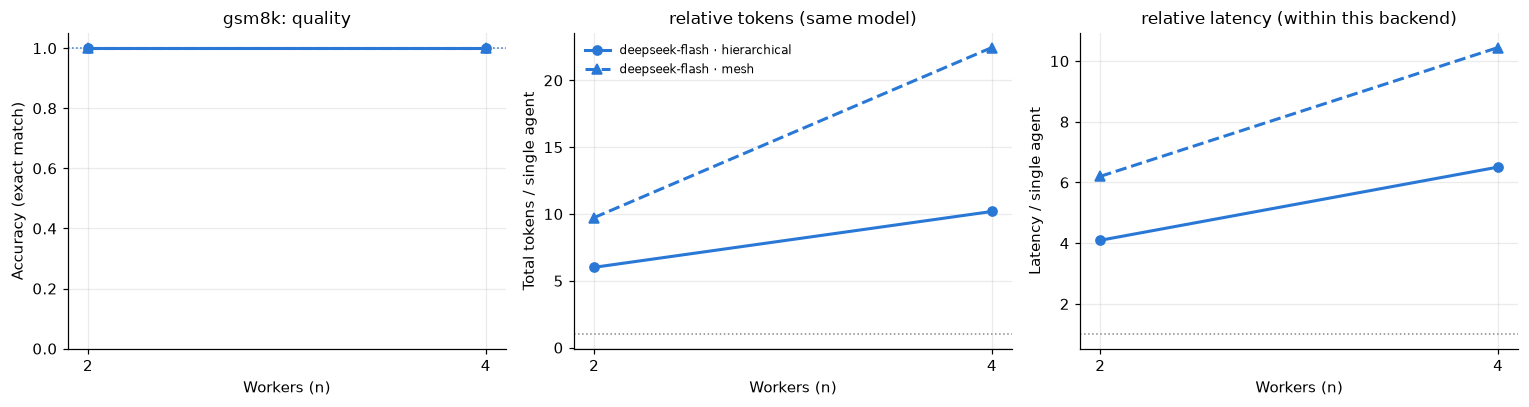

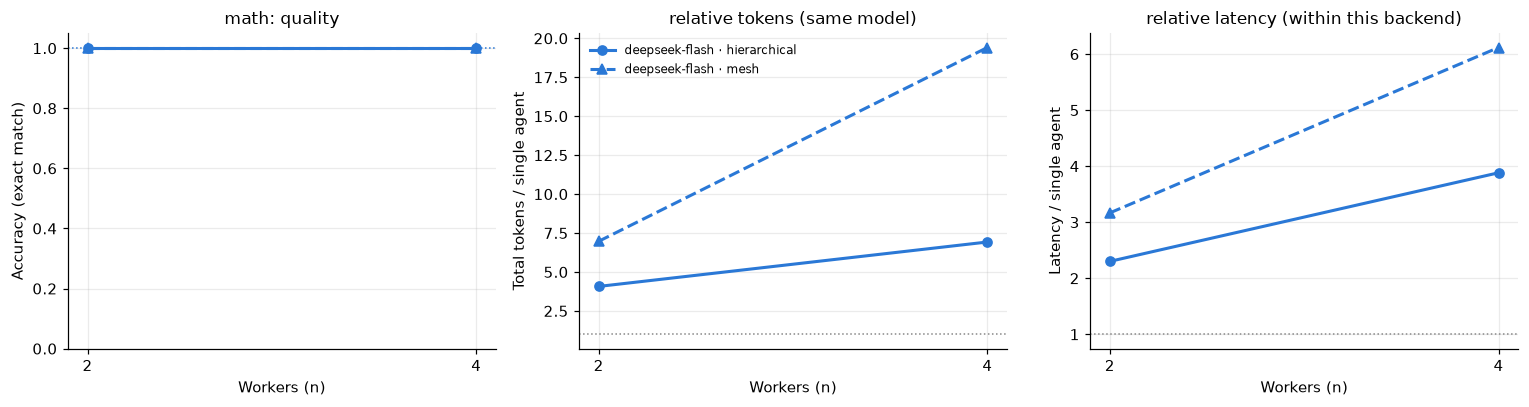

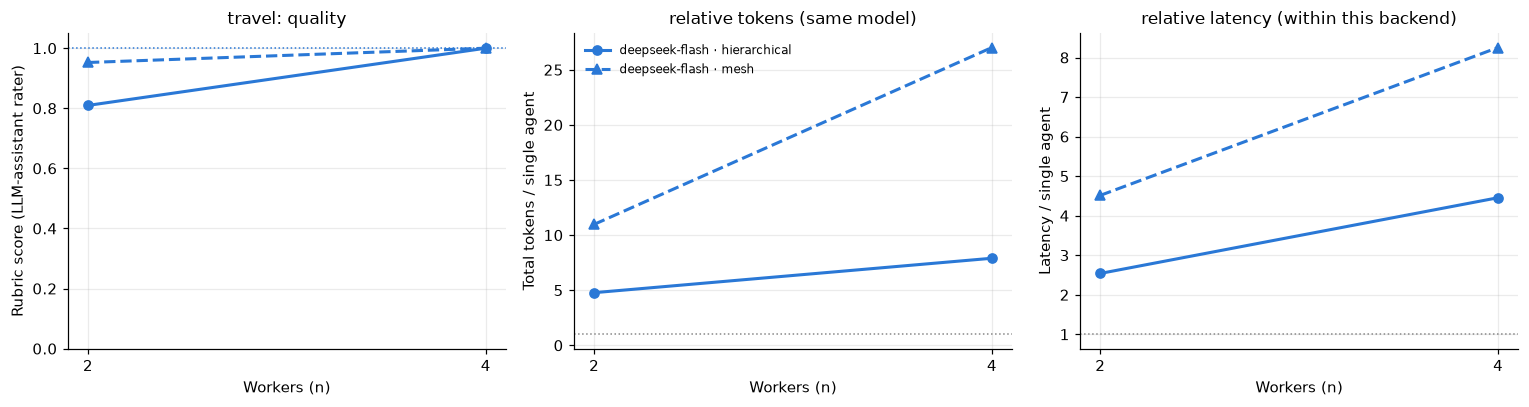

In [27]:
# Figure 1. Growth with n: quality, relative tokens and relative latency (three panels, no dual axes)
for d in DOMS:
    s = summary[summary.domain == d]
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
    for m in GENERATORS:
        sm = s[s.model == m]
        base = sm[sm.arch == "single"]
        for arch in ARCHITECTURES:
            sa = sm[sm.arch == arch].sort_values("n")
            if sa.empty: continue
            kw = dict(color=MODEL_COLOR[m], lw=2, ms=6, **ARCH_STYLE[arch], label=f"{m} · {arch}")
            if sa.quality.notna().any():
                axes[0].plot(sa.n, sa.quality, **kw)
            axes[1].plot(sa.n, sa.total_tokens_x_single, **kw)
            axes[2].plot(sa.n, sa.latency_total_s_x_single, **kw)
        if len(base) and base.quality.notna().any():
            axes[0].axhline(base.quality.iloc[0], color=MODEL_COLOR[m], lw=1, ls=":", label=f"{m} · single")
    for ax in axes[1:]:
        ax.axhline(1, color="#888", lw=1, ls=":")
    axes[0].set(xlabel="Workers (n)", ylabel=QLABEL[d], title=f"{d}: quality" + STAMP, ylim=(0, 1.05))
    axes[1].set(xlabel="Workers (n)", ylabel="Total tokens / single agent", title="relative tokens (same model)")
    axes[2].set(xlabel="Workers (n)", ylabel="Latency / single agent", title="relative latency (within this backend)")
    for ax in axes: ax.set_xticks(N_WORKERS)
    if s.quality.isna().all():
        axes[0].text(0.5, 0.5, "pending rubric evaluation", ha="center", va="center", transform=axes[0].transAxes, color="#888")
    axes[1].legend(fontsize=8)
    fig.tight_layout(); save(fig, f"growth_{d}"); plt.show()

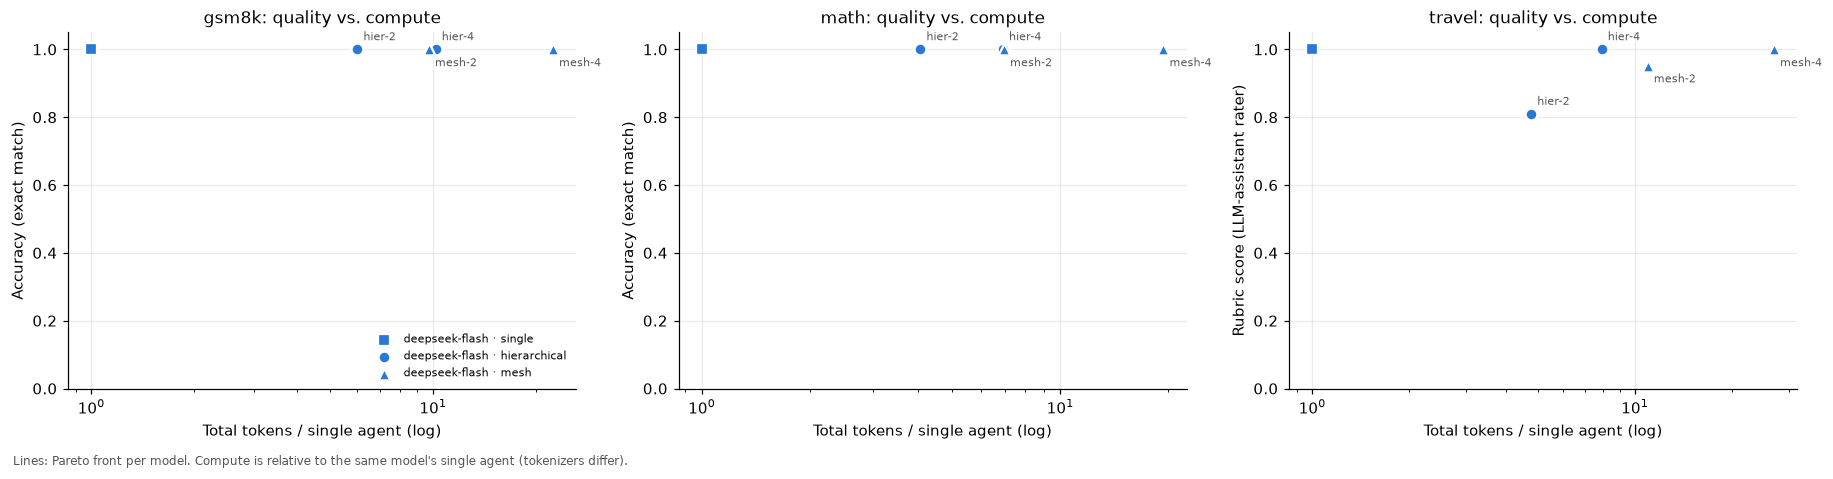

In [28]:
# Figure 2. Quality vs. relative computational cost, with each model's Pareto front
def pareto_front(df, x, y):
    df = df.dropna(subset=[x, y]).sort_values([x, y], ascending=[True, False])
    front, best = [], -np.inf
    for _, r in df.iterrows():
        if r[y] > best:
            front.append(r.config); best = r[y]
    return front

fig, axes = plt.subplots(1, len(DOMS), figsize=(5.6 * len(DOMS), 4.2), squeeze=False)
for ax, d in zip(axes[0], DOMS):
    s = summary[summary.domain == d]
    if s.quality.isna().all():
        ax.text(0.5, 0.5, "pending rubric evaluation", ha="center", va="center", transform=ax.transAxes, color="#888")
    for m in GENERATORS:
        sm = s[s.model == m].dropna(subset=["quality"])
        if sm.empty: continue
        for arch, mk in (("single", "s"), ("hierarchical", "o"), ("mesh", "^")):
            sa = sm[sm.arch == arch]
            ax.scatter(sa.total_tokens_x_single, sa.quality, color=MODEL_COLOR[m], marker=mk, s=60,
                       edgecolor="white", linewidth=1.5, zorder=3, label=f"{m} · {arch}")
            for _, r in sa.iterrows():
                if arch != "single":
                    ax.annotate(r.config, (r.total_tokens_x_single, r.quality), textcoords="offset points",
                                xytext=(4, 6 if arch == "hierarchical" else -11), fontsize=7, color="#555")
        front = sm.set_index("config").loc[pareto_front(sm, "total_tokens_x_single", "quality")]
        ax.plot(front.total_tokens_x_single, front.quality, color=MODEL_COLOR[m], lw=1, drawstyle="steps-post", alpha=0.7)
    ax.set(xscale="log", xlabel="Total tokens / single agent (log)", ylabel=QLABEL[d], title=f"{d}: quality vs. compute" + STAMP,
           ylim=(0, 1.05))
axes[0][0].legend(fontsize=7, loc="lower right")
fig.text(0.01, -0.02, "Lines: Pareto front per model. Compute is relative to the same model's single agent (tokenizers differ).", fontsize=8, color="#555")
fig.tight_layout(); save(fig, "pareto"); plt.show()

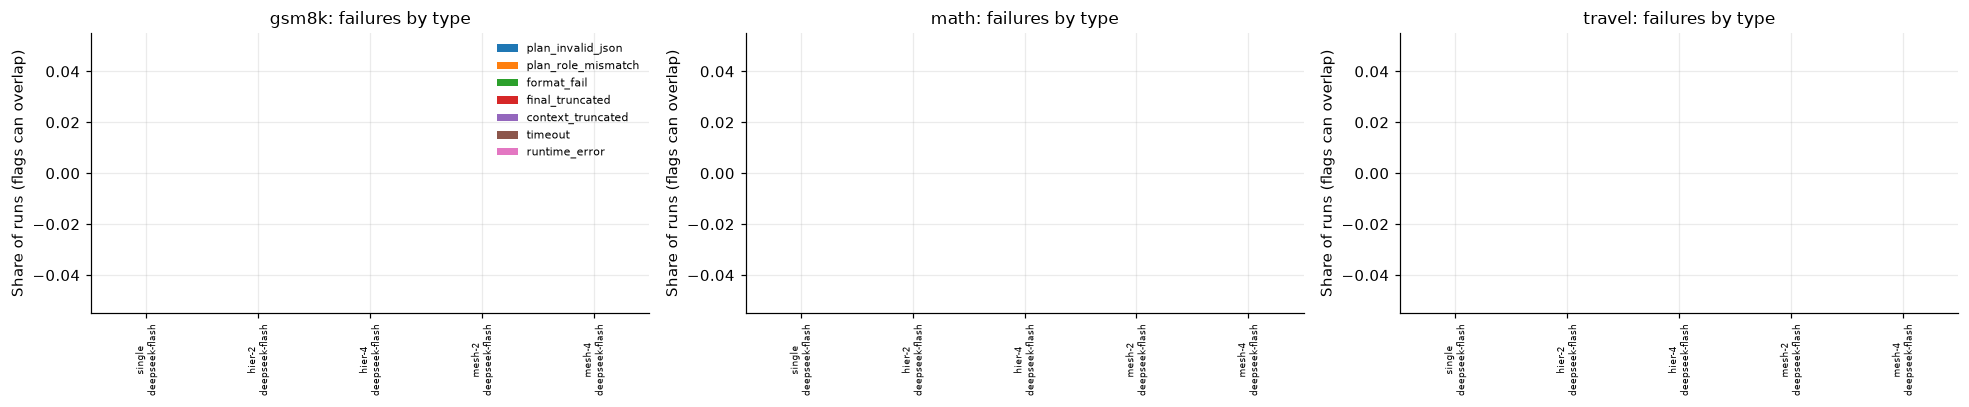

In [29]:
# Figure 3. Failure rates by type, configuration and model
show_flags = ["plan_invalid_json", "plan_role_mismatch", "format_fail", "final_truncated", "context_truncated", "timeout", "runtime_error"]
fig, axes = plt.subplots(1, len(DOMS), figsize=(6 * len(DOMS), 3.8), squeeze=False)
for ax, d in zip(axes[0], DOMS):
    s = summary[summary.domain == d]
    labels, x = [], 0
    for cfg in CONFIGS:
        for m in GENERATORS:
            r = s[(s.config == cfg) & (s.model == m)]
            bottom = 0
            for i, f in enumerate(show_flags):
                v = r[f"rate_{f}"].iloc[0] if len(r) else 0
                ax.bar(x, v, bottom=bottom, color=plt.cm.tab10(i), width=0.8, label=f if (cfg, m) == (CONFIGS[0], GENERATORS[0]) else None)
                bottom += v
            labels.append(f"{cfg}\n{m.split(':')[0]}"); x += 1
        x += 0.5
    ticks = [i + 0.5 * (i // len(GENERATORS)) for i in range(len(labels))]
    ax.set_xticks(ticks, labels, fontsize=6, rotation=90)
    ax.set(ylabel="Share of runs (flags can overlap)", title=f"{d}: failures by type" + STAMP)
axes[0][0].legend(fontsize=7)
fig.tight_layout(); save(fig, "failures"); plt.show()

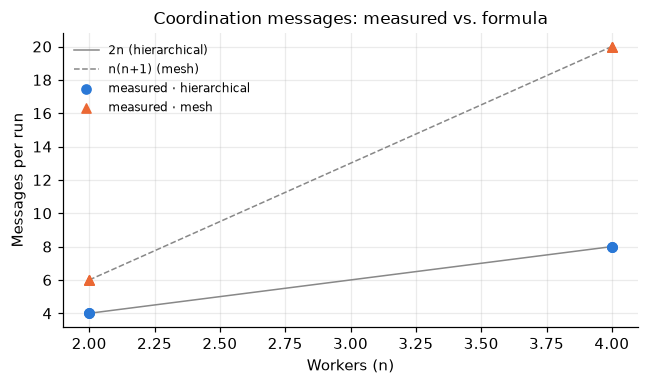

Messages and calls match the formulas in every configuration.


In [30]:
# Figure 4. Messages and calls: measured vs. formula (instrumentation check)
s = summary[summary.arch != "single"]
if len(s):
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ns = np.array(N_WORKERS)
    ax.plot(ns, 2 * ns, color="#888", lw=1, label="2n (hierarchical)")
    ax.plot(ns, ns * (ns + 1), color="#888", lw=1, ls="--", label="n(n+1) (mesh)")
    for arch in ARCHITECTURES:
        sa = s[s.arch == arch]
        ax.scatter(sa.n, sa.n_messages, color="#2a78d6" if arch == "hierarchical" else "#eb6834", zorder=3,
                   marker=ARCH_STYLE[arch]["marker"], label=f"measured · {arch}")
    ax.set(xlabel="Workers (n)", ylabel="Messages per run", title="Coordination messages: measured vs. formula" + STAMP)
    ax.legend(fontsize=8); fig.tight_layout(); save(fig, "messages"); plt.show()
    expect_msgs = np.where(s.arch == "mesh", s.n * (s.n + 1), 2 * s.n)
    expect_calls = np.where(s.arch == "mesh", 2 * s.n + 2, s.n + 2)
    ok = (s.n_messages == expect_msgs).all() and (s.n_calls == expect_calls).all()
    print("Messages and calls match the formulas in every configuration." if ok else "Mismatch with the formulas: check the trace.")

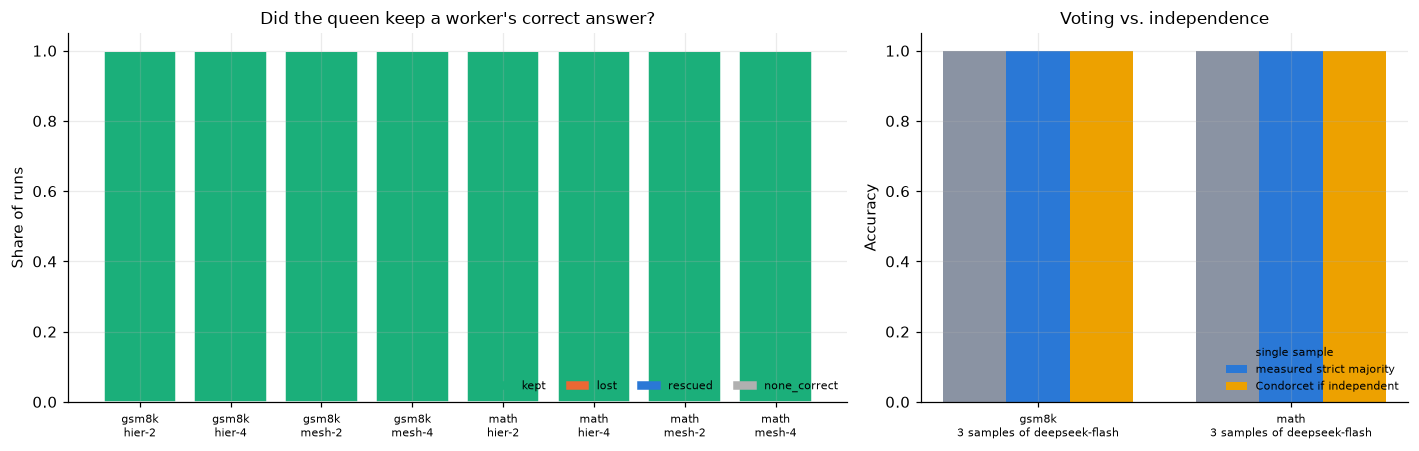

In [31]:
# Figure 5. Coordination outcomes on the verifiable tasks and the Condorcet check
if coord is not None and len(coord):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[1.6, 1]))
    cats, colors = ["kept", "lost", "rescued", "none_correct"], ["#1baf7a", "#eb6834", "#2a78d6", "#b0b0b0"]
    labels = []
    for x, idx in enumerate(coord.index):
        bottom = 0
        for c, col in zip(cats, colors):
            ax1.bar(x, coord.loc[idx, c], bottom=bottom, color=col, width=0.8, edgecolor="white", linewidth=1)
            bottom += coord.loc[idx, c]
        labels.append(f"{idx[0]}\n{idx[2]}" + (f"\n{idx[1].split(':')[0]}" if len(GENERATORS) > 1 else ""))
    ax1.set_xticks(range(len(labels)), labels, fontsize=7)
    ax1.set(ylabel="Share of runs", ylim=(0, 1.05), title="Did the queen keep a worker's correct answer?" + STAMP)
    from matplotlib.patches import Patch
    ax1.legend(handles=[Patch(color=col, label=c) for c, col in zip(cats, colors)], fontsize=7, loc="lower right", ncol=4)
    if voting is not None and len(voting):
        xv = np.arange(len(voting))
        ax2.bar(xv - 0.25, voting.single_acc, 0.25, color="#8a93a3", label="single sample")
        ax2.bar(xv, voting.majority_acc, 0.25, color="#2a78d6", label="measured strict majority")
        ax2.bar(xv + 0.25, voting.condorcet_if_independent, 0.25, color="#eda100", label="Condorcet if independent")
        ax2.set_xticks(xv, voting.ensemble.str.replace(": ", "\n"), fontsize=7)
        ax2.set(ylim=(0, 1.05), ylabel="Accuracy", title="Voting vs. independence" + STAMP)
        ax2.legend(fontsize=7, loc="lower right")
    fig.tight_layout(); save(fig, "coordination_voting"); plt.show()


## 12. Data-derived statements

The cell below **derives** statements from the data. It contains no hand-written numbers.
- Engineering agnosticism is shown by coverage: the same code ran DeepSeek (full grid) and the two local models (pilot).
- The cost–quality conclusions come from the DeepSeek grid only. Cross-model statements are exploratory.

In [32]:
print(("⚠ MOCK DATA: statements below only show that the analysis works.\n" if IS_MOCK else "") + "=" * 78)
full_cov = (cov.fillna(0) > 0).all().all() if len(cov) else False
print(f"Engineering agnosticism: {'every' if full_cov else 'NOT every'} configuration ran with "
      f"{', '.join(GENERATORS)} using identical orchestration code (only GENERATORS changes).")
for _, r in optimal.iterrows():
    print(f"[{r.model} · {r.domain}] best: {r.best_config} ({r.best_quality:.2f}); cheapest within 95%: "
          f"{r.optimal_config} ({r.optimal_quality:.2f}, {r.optimal_tokens_x_single:.1f}× the single agent's tokens).")
if "cost_usd_list_x_single" in summary:
    for (m, d), g in summary[summary.arch != "single"].groupby(["model", "domain"]):
        if g.cost_usd_list.sum() > 0:
            print(f"[{m} · {d}] cost per run grows to {g.cost_usd_list_x_single.min():.1f}–{g.cost_usd_list_x_single.max():.1f}× "
                  f"the single agent (list price).")
    print(f"Cartagena quality source: {RUBRIC_SOURCE or 'pending'}.")
    print(f"Total recorded spend (spend_ledger.jsonl): ${SPENT['usd']:.4f} of the ${MAX_SPEND_USD:.2f} cap.")
for (m, d), g in summary[summary.arch != "single"].groupby(["model", "domain"]):
    print(f"[{m} · {d}] tokens grow to {g.total_tokens_x_single.min():.1f}–{g.total_tokens_x_single.max():.1f}× the single agent; "
          f"technical failures {g.rate_technical_failure.min():.0%}–{g.rate_technical_failure.max():.0%}.")
if len(stability):
    for _, r in stability.iterrows():
        print(f"Empirical agnosticism [{r.domain} · {r.metric}]: " + (f"Kendall τ = {r.kendall_tau:.2f} over {r.configs} configurations."
              if not np.isnan(r.kendall_tau) else r.note + "."))
trunc = summary[summary.rate_context_truncated > 0]
print("Context truncation: none." if trunc.empty else
      "Context truncation in: " + ", ".join(f"{r.model}/{r.domain}/{r.config} ({r.rate_context_truncated:.0%})" for _, r in trunc.iterrows()))

Engineering agnosticism: every configuration ran with deepseek-flash using identical orchestration code (only GENERATORS changes).
[deepseek-flash · gsm8k] best: single (1.00); cheapest within 95%: single (1.00, 1.0× the single agent's tokens).
[deepseek-flash · math] best: single (1.00); cheapest within 95%: single (1.00, 1.0× the single agent's tokens).
[deepseek-flash · travel] best: single (1.00); cheapest within 95%: single (1.00, 1.0× the single agent's tokens).
[deepseek-flash · gsm8k] cost per run grows to 5.1–16.6× the single agent (list price).
[deepseek-flash · math] cost per run grows to 2.7–9.4× the single agent (list price).
[deepseek-flash · travel] cost per run grows to 3.5–14.5× the single agent (list price).
Cartagena quality source: LLM assistant (Claude Opus 5.5, blind).
Total recorded spend (spend_ledger.jsonl): $0.2221 of the $0.50 cap.
[deepseek-flash · gsm8k] tokens grow to 6.0–22.5× the single agent; technical failures 0%–0%.
[deepseek-flash · math] tokens grow

**Limitations to state in the paper:**
- **Ceiling effects.** DeepSeek-Flash solved every GSM8K-Platinum problem and every sampled MATH level-5 problem in every configuration, including the single agent. On these tasks the experiment can show the *cost* of coordination but cannot show a quality *gain*; McNemar has no discordant pairs. Tasks where the single agent fails (e.g. AIME-level problems) would need longer outputs and exceed this study's budget cap.
- **Models:** the full grid runs on one API model (`deepseek-flash`, non-thinking). The two 3B local models only ran a one-task pilot, so empirical model agnosticism is exploratory evidence, not a measured result.
- **Open-task quality:** one task (Cartagena), 3 repetitions per configuration. The rubric was applied blind by **one LLM assistant (Claude Opus 5.5), not by humans**; the notebook switches to the human ratings automatically when `ratings_rater1.csv` / `ratings_rater2.csv` are filled in. The LLM judge (DeepSeek judging its own answers) is secondary.
- **Repetitions:** MATH swarm configurations ran once per problem (10 runs each) because two repetitions did not fit the budget cap.
- **Comparability:** tokenizers differ, so absolute tokens are compared only within a model. Latency is compared only within a backend: API latency also depends on server load, which the random run order spreads over all configurations.
- **Reproducibility:** the DeepSeek API has no seed, so repetitions are independent samples. Context caching lowers the billed cost of repeated prefixes, so configurations are compared at the list price (`cost_usd_list`).
- **Contamination:** GSM8K and MATH may be in the model's training data.

## 13. Conclusions

Values below come from the executed run of 2026-10-07 (195 DeepSeek runs, 0 technical failures) and match the tables above.

**Answer to the research question.** For `deepseek-flash`, adding agents and communication **did not improve quality in any domain**, while it multiplied the cost:

| Domain | Single-agent quality | Best swarm quality | Tokens vs. single | Cost vs. single (list price) | Latency vs. single |
|---|---|---|---|---|---|
| GSM8K-Platinum | 1.00 | 1.00 (all configurations) | 6.0× – 22.5× | 5.1× – 16.6× | 4.1× – 10.4× |
| MATH-500 level 5 | 1.00 | 1.00 (all configurations) | 4.1× – 19.4× | 2.7× – 9.4× | 2.3× – 6.1× |
| Cartagena (rubric, LLM-assistant rater) | 1.00 | 1.00 (hier-4, mesh-4); hier-2 0.81, mesh-2 0.95 | 4.8× – 27.0× | 3.5× – 14.5× | 2.5× – 8.3× |

The cost–quality optimum (the cheapest configuration within 95% of the best quality) is the **single agent in all three domains**.

**Hypotheses.**

| # | Verdict | Evidence |
|---|---|---|
| H1 | **Supported** | Calls and messages match 2n / n(n+1) exactly. From n = 2 to n = 4, relative tokens grow 6.0→10.2× (hier) vs. 9.7→22.5× (mesh) on GSM8K, 4.1→6.9× vs. 7.0→19.4× on MATH, 4.8→7.9× vs. 11.0→27.0× on Cartagena: mesh grows about twice as fast. |
| H2 | **Consistent, but limited by the ceiling** | GSM8K: 30/30 single samples and 80/80 swarm runs correct. Swarms add 5–17× cost and no accuracy. |
| H2b | **Not testable as planned** | MATH level 5 was also at the ceiling (30/30 single, 40/40 swarm). Internally, coordination did correct errors: in 8 of 40 swarm runs at least one worker gave a wrong or unmarked answer; in the 5 such mesh runs, the review round corrected every one of them (review improved 1 of 10 mesh-2 and 4 of 10 mesh-4 runs), and the queen always kept the correct answer. The redundancy works, but there was nothing to gain over the single agent. |
| H3 | **Not supported** (provisional: non-human rater) | No swarm beat the single agent on the rubric. hier-2 scored lowest (0.81; its three plans had budget inconsistencies or no risk mitigations). The LLM judge ranked the configurations differently (single 0.86, mesh-4 1.00), with low agreement on the risks criterion (κ = 0.36): judge scores are not ground truth. |
| H4 | **Not testable** (one model in the full grid) | Exploratory: in the local pilot, Llama produced invalid JSON plans in 2 of 4 GSM8K swarm runs and both 3B models lost a correct answer once; DeepSeek had 0 coordination failures in 132 swarm runs. Failure modes look model-dependent. |
| H5 | **Not testable** | Every sample was correct, so error correlation is undefined. |
| H6 | **Partly supported (exploratory)** | Small local models failed coordination formats (invalid JSON, role mismatch, truncated final answer). No context limit was reached at n ≤ 4 on DeepSeek (1M-token window), but mesh prompts grow fastest: the largest single prompt was 8,129 tokens (MATH, mesh-4, review stage). With a 1,024-token output it would not fit the 8,192-token window used for the local models (tokenizers differ, so this is indicative). Locally, the largest prompt in the pilot was 3,250 tokens. |

**Engineering agnosticism** is shown: the same orchestration code ran the DeepSeek API and two local Ollama models, changing only the configuration. **Empirical agnosticism** remains exploratory.

**Take-away for the paper.** With a capable model, coordination is a *cost* that must be justified by tasks the single agent cannot solve. On tasks it already solves, hierarchical swarms used 4–10× and meshes 7–27× the single agent's tokens for the same quality, and mesh cost grows quadratically with n. The internal error-correction we observed on MATH suggests where swarms could pay off (harder tasks with frequent single-agent errors), which this budget did not allow us to test.

Total recorded spend of the whole study (checks, pilots, grid, judge, demo): about **$0.22** billed (≈ $0.44 at list price), printed exactly in section 12.